# Analyse exploratoire des données — Agritech Answers

**Étape 1.** Description des **six fichiers** fournis, puis diagnostic de jointure. Ce notebook ne modifie aucune donnée : nettoyage, fusion et *feature engineering* relèvent de `data_preparation.ipynb`.

| § | Fichier | Granularité |
|---|---|---|
| 1 | Configuration et inventaire | — |
| 2 | `crop_yield.csv` — **jeu A** | Parcelle |
| 3 | `yield_df.csv` — **jeu B** | Pays × année × culture |
| 4 | `yield.csv` | Source FAO brute |
| 5 | `pesticides.csv` | Source brute |
| 6 | `rainfall.csv` | Source brute |
| 7 | `temp.csv` | Source brute |
| 8 | Reconstitution du jeu B et choix de la source | — |
| 9 | Clés de jointure disponibles | — |
| 10 | Analyse en composantes principales | — |
| 11 | Synthèse | — |

## 1. Configuration et inventaire

In [1]:
# Le projet est installe en mode editable par `uv sync`. Repli au cas ou le
# noyau selectionne ne serait pas celui du projet : on ajoute src/ au chemin.
try:
    import agritech  # noqa: F401
except ModuleNotFoundError:
    import sys
    from pathlib import Path
    _racine = next(p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'pyproject.toml').exists())
    sys.path.insert(0, str(_racine / 'src'))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats

from agritech.config import (
    ALL_SOURCES,
    BLUE,
    BOOLEAN_FEATURES,
    CATEGORICAL_FEATURES,
    CROP_MAPPING,
    CROP_YIELD_PATH,
    GREEN,
    HG_PER_HA_TO_T_PER_HA,
    NUMERIC_COLUMNS,
    NUMERIC_FEATURES,
    ORANGE,
    PESTICIDES_PATH,
    PROJECT_ROOT,
    RAINFALL_PATH,
    RANDOM_STATE,
    TARGET,
    TEMP_PATH,
    YIELD_DF_PATH,
    YIELD_RAW_PATH,
)

# Affichage : toutes les colonnes, 3 decimales
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: format(v, ',.3f'))

# Style graphique unifie sur tout le notebook
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

SAMPLE_SIZE = 50_000   # specifique a l'EDA : echantillon pour les graphiques lourds


In [2]:
# Echec immediat et explicite si un fichier source manque
for path in ALL_SOURCES.values():
    assert path.exists(), 'Fichier introuvable : ' + str(path)

print('Racine du projet :', PROJECT_ROOT)
print('Fichiers sources :', len(ALL_SOURCES), 'presents')

Racine du projet : C:\Users\faiza\Formation_IA\Projet12_mission
Fichiers sources : 6 presents


In [3]:
def profile_dataframe(df):
    # Fiche d'identite colonne par colonne : type, manquants, modalites, memoire
    return pd.DataFrame({
        'type': df.dtypes.astype(str),
        'non_nuls': df.notna().sum(),
        'nan': df.isna().sum(),
        'nan_pct': (100 * df.isna().mean()).round(2),
        'uniques': df.nunique(),
        'uniques_pct': (100 * df.nunique() / len(df)).round(2),
        'memoire_mo': (df.memory_usage(deep=True, index=False) / 1024 ** 2).round(2),
        'exemple': df.iloc[0],
    })


def summarize(df, name):
    # Vue d'ensemble : volume, memoire, manquants globaux, doublons
    missing = int(df.isna().sum().sum())
    print(name)
    print('  dimensions          :', format(df.shape[0], ',d'), 'lignes x', df.shape[1], 'colonnes')
    print('  memoire             :', round(df.memory_usage(deep=True).sum() / 1024 ** 2, 1), 'Mo')
    print('  cellules manquantes :', format(missing, ',d'),
          '(' + format(100 * missing / df.size, '.4f') + ' % du total)')
    print('  colonnes avec NaN   :', int((df.isna().sum() > 0).sum()), 'sur', df.shape[1])
    print('  lignes dupliquees   :', format(df.duplicated().sum(), ',d'))


def eta_squared(df, factor, target):
    # Part de la variance de `target` expliquee par la qualitative `factor`
    grand_mean = df[target].mean()
    grouped = df.groupby(factor, observed=True)[target]
    ss_between = (grouped.count() * (grouped.mean() - grand_mean) ** 2).sum()
    ss_total = ((df[target] - grand_mean) ** 2).sum()
    return ss_between / ss_total


def constant_columns(df):
    # Colonnes a valeur unique : aucune information, donc supprimables
    return [col for col in df.columns if df[col].nunique(dropna=False) <= 1]


def duplicate_report(df, subset):
    # Deux niveaux : lignes strictement identiques, et cles metier repetees.
    # Une cle repetee avec des valeurs differentes n'est pas un doublon technique
    # mais une incoherence de donnees.
    on_key = int(df.duplicated(subset=list(subset)).sum())
    return pd.Series({
        'lignes': len(df),
        'doublons_stricts': int(df.duplicated().sum()),
        'doublons_sur_cle': on_key,
        'lignes_impliquees': int(df.duplicated(subset=list(subset), keep=False).sum()),
        'cles_uniques': len(df) - on_key,
    }, name='doublons')

### 1.1 Les six fichiers

Le dossier contient **six** fichiers, et non deux : les deux jeux annoncés, plus les quatre sources brutes ayant servi à construire `yield_df.csv`.

In [4]:
# Inventaire : volume, structure et poids sur disque
inventory = []
for name, path in ALL_SOURCES.items():
    header = pd.read_csv(path, nrows=0)             # en-tete seul : certains fichiers sont volumineux
    n_rows = sum(1 for _ in path.open('rb')) - 1    # comptage binaire, insensible a l'encodage
    inventory.append({
        'fichier': name,
        'lignes': n_rows,
        'colonnes': header.shape[1],
        'poids_mo': round(path.stat().st_size / 1024 ** 2, 2),
        'noms_colonnes': ', '.join(header.columns),
    })

pd.DataFrame(inventory).set_index('fichier')

,lignes,colonnes,poids_mo,noms_colonnes
fichier,,,,
crop_yield.csv (jeu A),1000000,10,89.080,"Region, Soil_Type, Crop, Rainfall_mm, Temperat..."
"yield_df.csv (jeu B, fusionné)",28242,8,1.490,"Unnamed: 0, Area, Item, Year, hg/ha_yield, ave..."
yield.csv (brut FAO),56717,12,3.860,"Domain Code, Domain, Area Code, Area, Element ..."
pesticides.csv (brut),4349,7,0.430,"Domain, Area, Element, Item, Year, Unit, Value"
rainfall.csv (brut),6727,3,0.130,"Area, Year, average_rain_fall_mm_per_year"
temp.csv (brut),71311,3,1.360,"year, country, avg_temp"


## 2. `crop_yield.csv` — jeu A

Granularité **parcelle**. C'est le jeu qui porte la variable cible de l'application : `Yield_tons_per_hectare`.

### 2.1 Structure et qualité

In [5]:
crop_yield = pd.read_csv(CROP_YIELD_PATH)
moyenne_globale = crop_yield[TARGET].mean()

print(format(crop_yield.shape[0], ',d'), 'lignes x', crop_yield.shape[1], 'colonnes')
crop_yield.head()

1,000,000 lignes x 10 colonnes


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077,27.677,False,True,Cloudy,122,6.556
1,South,Clay,Rice,992.673,18.026,True,True,Rainy,140,8.527
2,North,Loam,Barley,147.998,29.794,False,False,Sunny,106,1.127
3,North,Sandy,Soybean,986.866,16.644,False,True,Rainy,146,6.518
4,South,Silt,Wheat,730.379,31.621,True,True,Cloudy,110,7.248


In [6]:
summarize(crop_yield, 'crop_yield.csv — jeu A')
print()
profile_dataframe(crop_yield)

crop_yield.csv — jeu A
  dimensions          : 1,000,000 lignes x 10 colonnes


  memoire             : 238.4 Mo
  cellules manquantes : 0 (0.0000 % du total)
  colonnes avec NaN   : 0 sur 10


  lignes dupliquees   : 0



,type,non_nuls,nan,nan_pct,uniques,uniques_pct,memoire_mo,exemple
Region,str,1000000,0,0.000,4,0.000,51.020,West
Soil_Type,str,1000000,0,0.000,6,0.000,51.180,Sandy
Crop,str,1000000,0,0.000,6,0.000,51.970,Cotton
Rainfall_mm,float64,1000000,0,0.000,1000000,100.000,7.630,897.077
Temperature_Celsius,float64,1000000,0,0.000,1000000,100.000,7.630,27.677
Fertilizer_Used,bool,1000000,0,0.000,2,0.000,0.950,False
Irrigation_Used,bool,1000000,0,0.000,2,0.000,0.950,True
Weather_Condition,str,1000000,0,0.000,3,0.000,51.820,Cloudy
Days_to_Harvest,int64,1000000,0,0.000,90,0.010,7.630,122
Yield_tons_per_hectare,float64,1000000,0,0.000,1000000,100.000,7.630,6.556


In [7]:
crop_yield[NUMERIC_COLUMNS].describe().T

,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,"1,000,000.000",549.982,259.851,100.001,324.891,550.124,774.739,999.998
Temperature_Celsius,"1,000,000.000",27.505,7.221,15.000,21.255,27.507,33.753,40.000
Days_to_Harvest,"1,000,000.000",104.495,25.953,60.000,82.000,104.000,127.000,149.000
Yield_tons_per_hectare,"1,000,000.000",4.649,1.697,-1.148,3.418,4.652,5.879,9.963


In [8]:
# Valeurs physiquement impossibles : un rendement ne peut pas etre negatif
negative = crop_yield[TARGET] < 0
print('Rendements negatifs :', format(negative.sum(), ',d'),
      '(' + format(100 * negative.mean(), '.4f') + ' %)')
print('Rendement minimum   :', round(crop_yield[TARGET].min(), 3), 't/ha')
print('Colonnes constantes :', constant_columns(crop_yield) or 'aucune')

Rendements negatifs : 231 (0.0231 %)
Rendement minimum   : -1.148 t/ha


Colonnes constantes : aucune


### 2.2 Distribution des variables
#### 2.2.1 Variables numériques

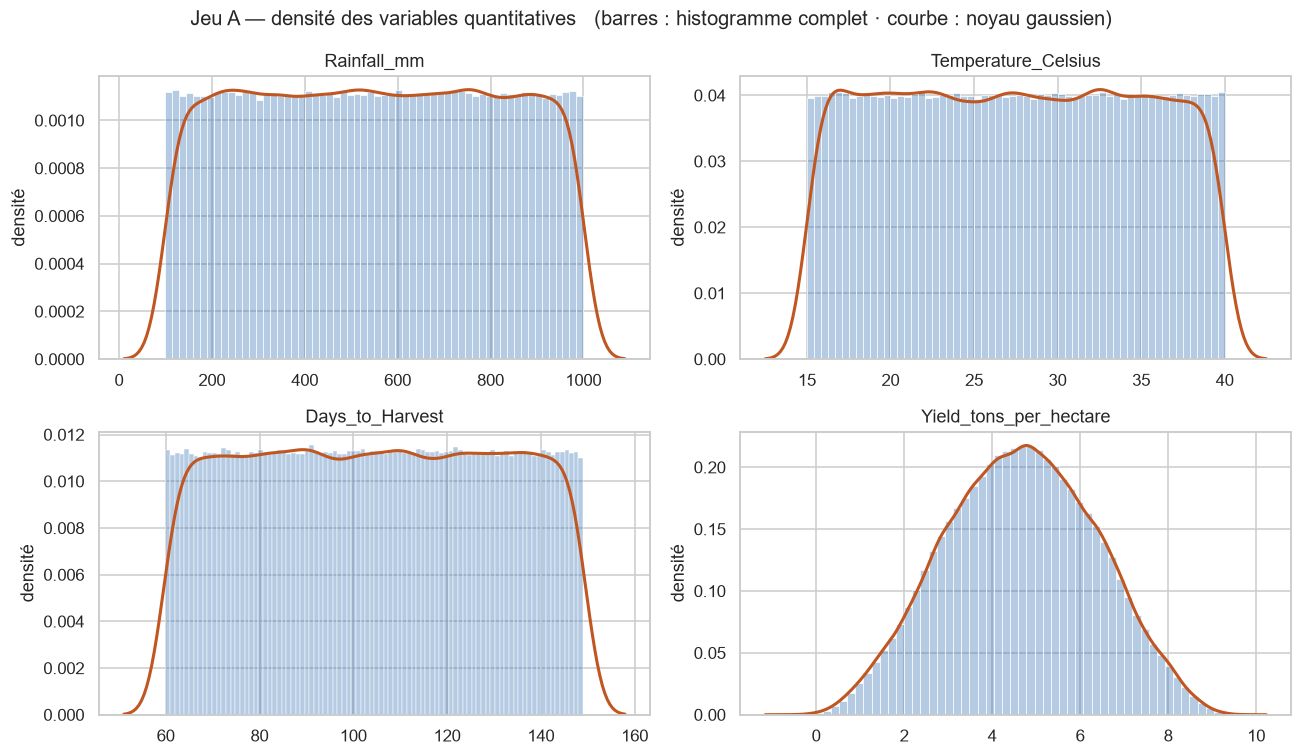

In [9]:
# Echantillon reutilise par les estimations de densite : sur 1M de lignes,
# un noyau gaussien sur l'integralite serait inutilement couteux
sample_a = crop_yield.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, NUMERIC_COLUMNS):
    # Une classe par valeur pour les variables entieres : 60 classes sur 90 valeurs
    # produiraient un effet de peigne purement artificiel
    classes = (crop_yield[col].nunique() if pd.api.types.is_integer_dtype(crop_yield[col])
               else 60)

    # Histogramme en densite sur la totalite des lignes, courbe lissee par-dessus
    sns.histplot(crop_yield[col], bins=classes, stat='density', ax=ax,
                 color=BLUE, alpha=0.35, edgecolor=None)
    sns.kdeplot(sample_a[col], ax=ax, color=ORANGE, linewidth=2)
    ax.set(title=col, xlabel='', ylabel='densité')

fig.suptitle('Jeu A — densité des variables quantitatives   '
             '(barres : histogramme complet · courbe : noyau gaussien)', fontsize=13)
fig.tight_layout()
plt.show()

> **Observation.** Les trois variables explicatives sont **uniformes** : pluie 100-1 000 mm, température 15-40 °C, durée 60-149 jours. Le rendement est symétrique autour de 4,65 t/ha.
>
> La courbe lissée **déborde des bornes** là où l'histogramme montre une coupure franche : artefact classique du noyau gaussien sur variable bornée. L'histogramme fait foi ici ; la courbe reste pertinente pour la cible, réellement lisse.

#### 2.2.2 Variables catégorielles

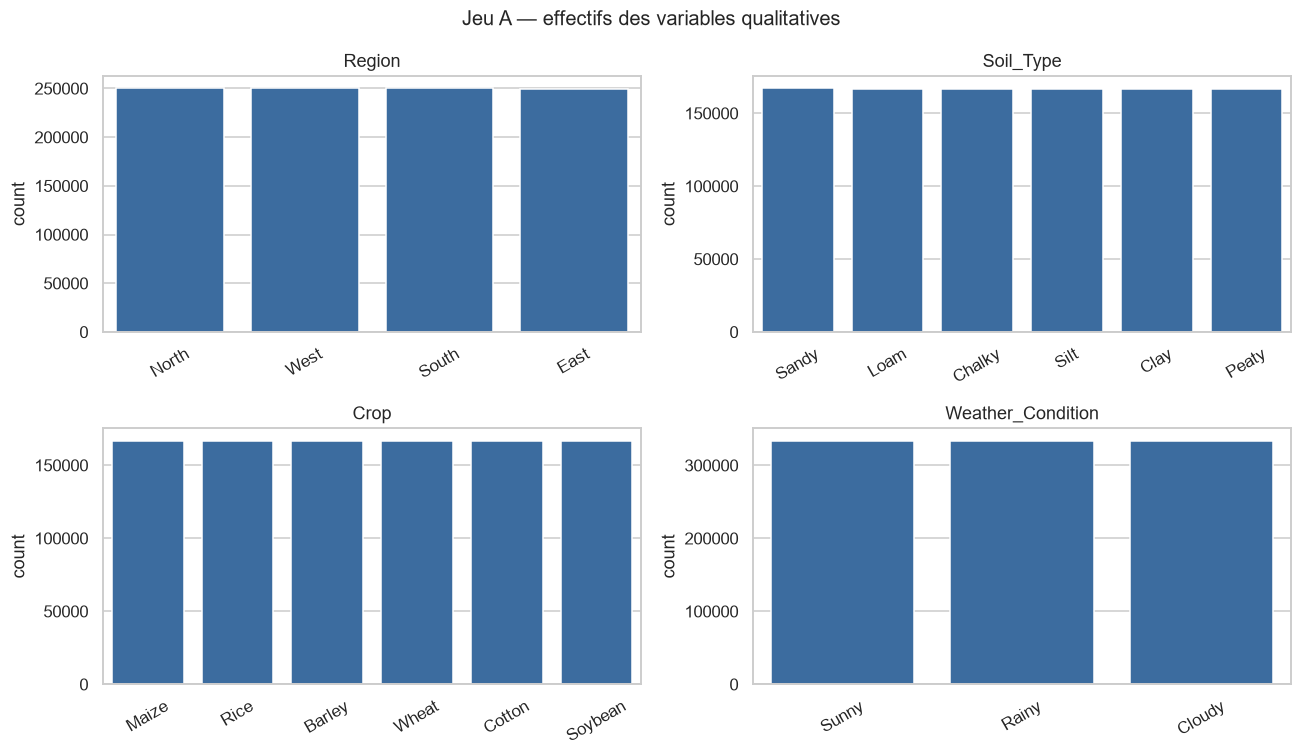

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, CATEGORICAL_FEATURES):
    order = crop_yield[col].value_counts().index
    sns.countplot(data=crop_yield, x=col, order=order, ax=ax, color=BLUE)
    ax.set(title=col, xlabel='')
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Jeu A — effectifs des variables qualitatives', fontsize=13)
fig.tight_layout()
plt.show()

> **Observation.** Les modalités sont **parfaitement équilibrées** : écarts aux effectifs théoriques inférieurs à 0,5 %. Combiné aux distributions uniformes, c'est la signature d'un jeu **simulé**, non d'observations de terrain.

### 2.3 Corrélations et forme des relations

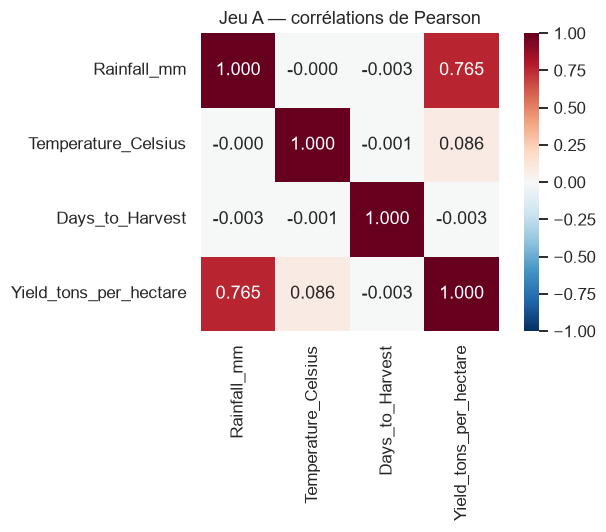

In [11]:
corr_a = crop_yield[NUMERIC_COLUMNS].corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr_a, annot=True, fmt='.3f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Jeu A — corrélations de Pearson')
fig.tight_layout()
plt.show()

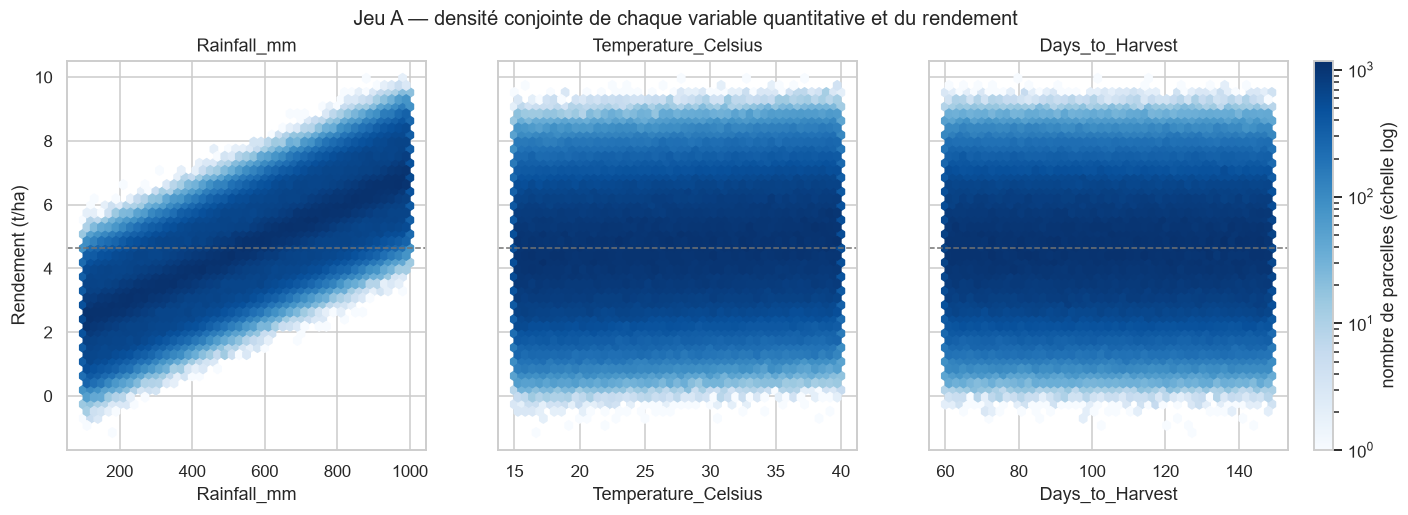

In [12]:
# Densite 2D sur la totalite des lignes : aucun decoupage arbitraire,
# contrairement a un nuage echantillonne ou a un regroupement en tranches
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)

for ax, col in zip(axes, NUMERIC_FEATURES):
    trace = ax.hexbin(crop_yield[col], crop_yield[TARGET], gridsize=45,
                      cmap='Blues', bins='log', mincnt=1)
    ax.axhline(moyenne_globale, color='0.45', linestyle='--', linewidth=1)
    ax.set(title=col, xlabel=col)

axes[0].set_ylabel('Rendement (t/ha)')
barre = fig.colorbar(trace, ax=axes, fraction=0.025, pad=0.02)
barre.set_label('nombre de parcelles (échelle log)')

fig.suptitle('Jeu A — densité conjointe de chaque variable quantitative et du rendement',
             fontsize=13)
plt.show()

> **Observation.** `Rainfall_mm` dessine une bande ascendante **rectiligne** — relation linéaire, non incurvée. `Temperature_Celsius` est à peine inclinée, `Days_to_Harvest` strictement horizontale.
>
> La **largeur** des bandes compte autant : même à pluie fixée, les rendements restent étalés sur plusieurs t/ha. Ce bruit irréductible plafonnera tout modèle, quelle que soit sa complexité.

### 2.4 Effet des variables qualitatives

In [13]:
import numpy as np

# Moyenne et intervalle de confiance a 95 % par modalite
rows = []
for var in BOOLEAN_FEATURES + CATEGORICAL_FEATURES:
    stats_var = crop_yield.groupby(var, observed=True)[TARGET].agg(['mean', 'std', 'count'])
    stats_var['ci95'] = 1.96 * stats_var['std'] / np.sqrt(stats_var['count'])
    for modalite, row in stats_var.iterrows():
        rows.append({'variable': var, 'modalite': str(modalite),
                     'moyenne': row['mean'], 'ci95': row['ci95']})

effets = pd.DataFrame(rows)

# Expression en ecart relatif : plus parlante qu'une difference en t/ha
effets['ecart_pct'] = 100 * (effets['moyenne'] / moyenne_globale - 1)
effets['ci_pct'] = 100 * effets['ci95'] / moyenne_globale

# Etendue des moyennes rapportee au bruit d'echantillonnage :
# un ratio proche de 1 signifie que l'ecart observe est indiscernable du hasard
resume = effets.groupby('variable').agg(
    etendue_pct=('ecart_pct', lambda s: s.max() - s.min()),
    demi_IC_pct=('ci_pct', 'mean'),
)
resume['ratio_etendue_sur_bruit'] = (resume['etendue_pct'] / resume['demi_IC_pct']).round(1)
resume.sort_values('ratio_etendue_sur_bruit', ascending=False)

,etendue_pct,demi_IC_pct,ratio_etendue_sur_bruit
variable,,,
Fertilizer_Used,32.264,0.091,355.600
Irrigation_Used,25.816,0.095,272.900
Crop,0.265,0.175,1.500
Region,0.183,0.143,1.300
Soil_Type,0.172,0.175,1.000
Weather_Condition,0.101,0.124,0.800


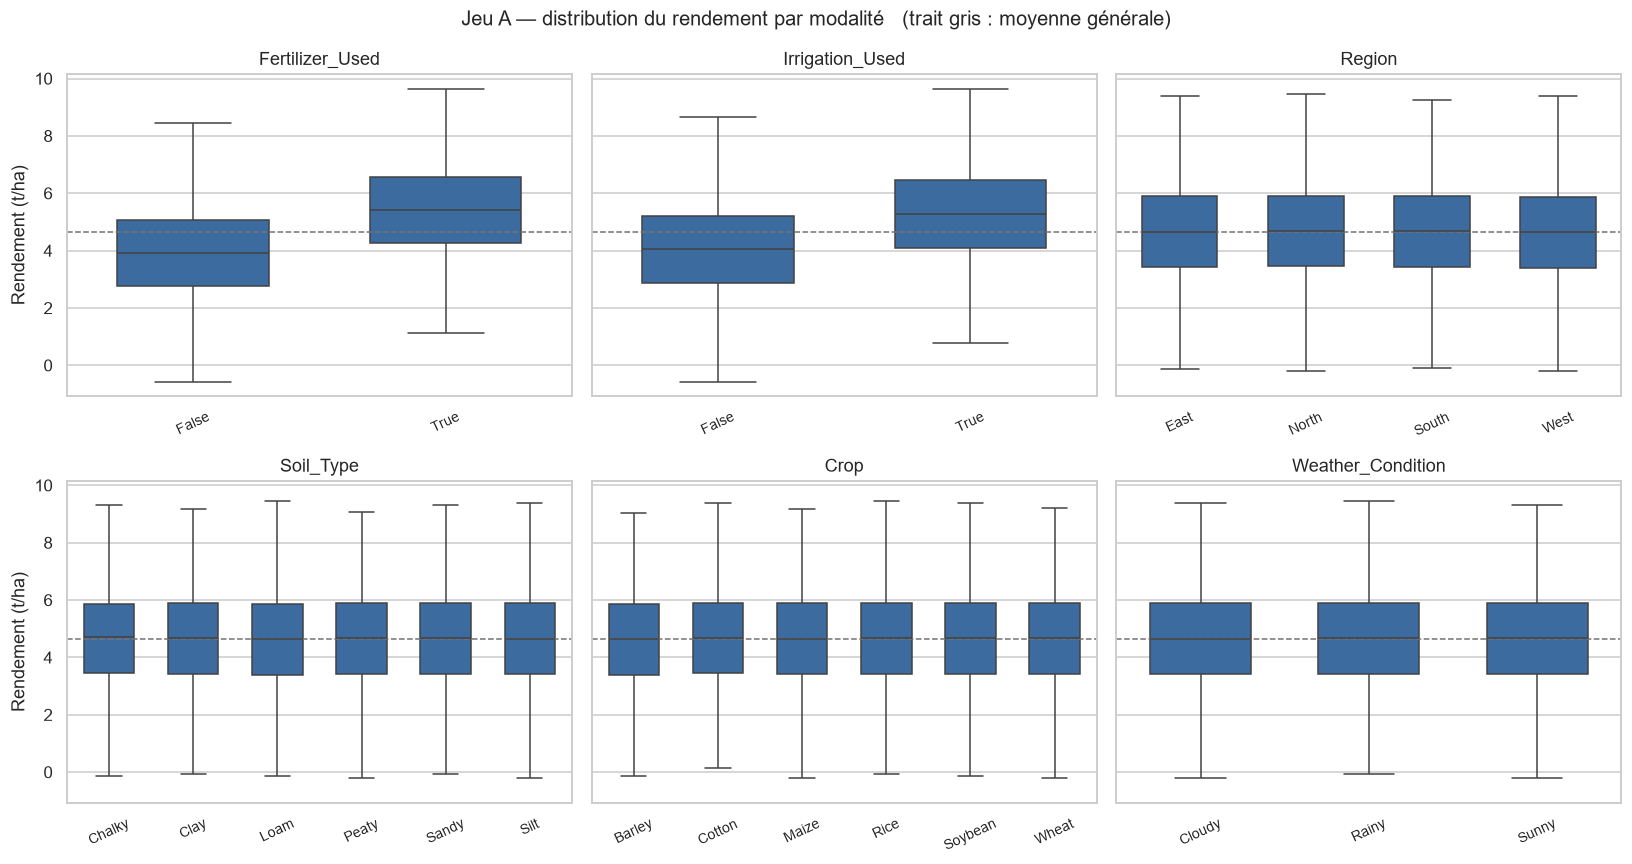

In [14]:
# Boxplot du rendement par modalite : une quantitative decoupee par une qualitative
variables = BOOLEAN_FEATURES + CATEGORICAL_FEATURES

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, col in zip(axes.flat, variables):
    ordre = sorted(crop_yield[col].unique().tolist())
    sns.boxplot(data=sample_a, x=col, y=TARGET, order=ordre, ax=ax,
                color=BLUE, width=0.6, showfliers=False)
    ax.axhline(moyenne_globale, color='0.45', linestyle='--', linewidth=1)
    ax.set(title=col, xlabel='')
    ax.tick_params(axis='x', rotation=25, labelsize=9)

for ax in axes[:, 0]:
    ax.set_ylabel('Rendement (t/ha)')

fig.suptitle('Jeu A — distribution du rendement par modalité   '
             '(trait gris : moyenne générale)', fontsize=13)
fig.tight_layout()
plt.show()

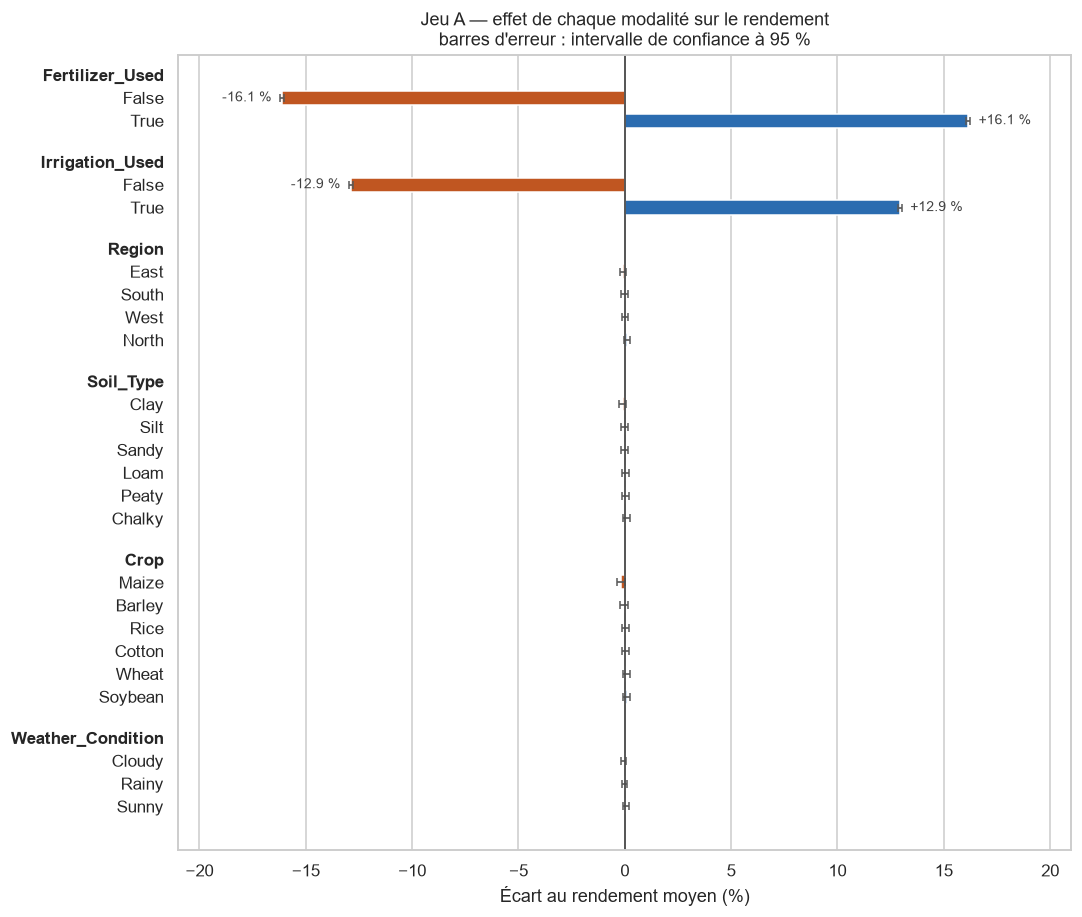

In [15]:
# Variables qualitatives : ecart au rendement moyen, en %.
# Encodage divergent (bleu au-dessus, orange en dessous), zero comme point neutre.
ticks, labels, entetes = [], [], []
y = 0.0

fig, ax = plt.subplots(figsize=(10, 8.5))

for var in BOOLEAN_FEATURES + CATEGORICAL_FEATURES:
    ticks.append(y); labels.append(var); entetes.append(True)
    y += 1

    sous_ensemble = effets[effets['variable'] == var].sort_values('ecart_pct')
    positions = y + np.arange(len(sous_ensemble))
    couleurs = [BLUE if valeur >= 0 else ORANGE for valeur in sous_ensemble['ecart_pct']]

    ax.barh(positions, sous_ensemble['ecart_pct'], color=couleurs, height=0.62,
            xerr=sous_ensemble['ci_pct'],
            error_kw={'ecolor': '0.35', 'elinewidth': 1.1, 'capsize': 2.5})

    # Etiquettes directes reservees aux effets notables, pour ne pas surcharger
    for position, valeur in zip(positions, sous_ensemble['ecart_pct']):
        if abs(valeur) > 1:
            ax.annotate(format(valeur, '+.1f') + ' %', (valeur, position),
                        xytext=(7 if valeur > 0 else -7, 0), textcoords='offset points',
                        va='center', ha='left' if valeur > 0 else 'right',
                        fontsize=9, color='0.25')

    for decalage, modalite in enumerate(sous_ensemble['modalite']):
        ticks.append(y + decalage); labels.append('    ' + modalite); entetes.append(False)
    y += len(sous_ensemble) + 0.8

ax.set_yticks(ticks)
ax.set_yticklabels(labels)
for etiquette, en_gras in zip(ax.get_yticklabels(), entetes):
    if en_gras:
        etiquette.set_fontweight('bold')

ax.invert_yaxis()
ax.axvline(0, color='0.3', linewidth=1.2)
ax.set_xlim(-21, 21)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Écart au rendement moyen (%)')
ax.set_title("Jeu A — effet de chaque modalité sur le rendement\n"
             "barres d'erreur : intervalle de confiance à 95 %", fontsize=12)
fig.tight_layout()
plt.show()

> **Lecture des deux figures.** Les boîtes sont nettement décalées pour `Fertilizer_Used` et `Irrigation_Used`, et **rigoureusement superposées** pour les quatre variables qualitatives.
>
> Les barres divergentes donnent l'ampleur en termes exploitables : **fertiliser vaut +16,1 %**, irriguer **+12,9 %**. Aucune modalité de `Crop`, `Region`, `Soil_Type` ou `Weather_Condition` ne dépasse **0,2 %**, et tous leurs intervalles de confiance recouvrent zéro.

In [16]:
# Taille d'effet : part de variance du rendement expliquee par chaque qualitative
factors = CATEGORICAL_FEATURES + BOOLEAN_FEATURES
effects = pd.Series({col: eta_squared(crop_yield, col, TARGET) for col in factors})
effects = effects.sort_values(ascending=False).to_frame('eta_carre')
effects['part_variance_pct'] = 100 * effects['eta_carre']
effects

,eta_carre,part_variance_pct
Fertilizer_Used,0.195,19.545
Irrigation_Used,0.125,12.513
Crop,0.000,0.001
Region,0.000,0.000
Soil_Type,0.000,0.000
Weather_Condition,0.000,0.000


In [17]:
# Test formel : le rendement differe-t-il selon la culture ?
groups_crop = [g[TARGET].to_numpy() for _, g in crop_yield.groupby('Crop', observed=True)]
f_crop, p_crop = stats.f_oneway(*groups_crop)
h_crop, p_kruskal = stats.kruskal(*groups_crop)   # non parametrique, sans hypothese de normalite

print('Crop — ANOVA           : F =', round(f_crop, 3), '| p =', round(p_crop, 4))
print('Crop — Kruskal-Wallis  : H =', round(h_crop, 3), '| p =', round(p_kruskal, 4))
print('Crop — taille d effet  : eta2 =', format(eta_squared(crop_yield, 'Crop', TARGET), '.6f'))
print()

# Contre-exemple : une variable qui, elle, porte un effet reel
groups_fert = [g[TARGET].to_numpy() for _, g in crop_yield.groupby('Fertilizer_Used', observed=True)]
f_fert, p_fert = stats.f_oneway(*groups_fert)

print('Fertilizer_Used — ANOVA          : F =', round(f_fert, 1), '| p =', p_fert)
print('Fertilizer_Used — taille d effet : eta2 =',
      format(eta_squared(crop_yield, 'Fertilizer_Used', TARGET), '.6f'))

Crop — ANOVA           : F = 1.179 | p = 0.3165
Crop — Kruskal-Wallis  : H = 5.581 | p = 0.3491
Crop — taille d effet  : eta2 = 0.000006



Fertilizer_Used — ANOVA          : F = 242933.1 | p = 0.0
Fertilizer_Used — taille d effet : eta2 = 0.195452


> **Lecture des tests.** Pour `Crop` : ANOVA **p = 0,32**, Kruskal-Wallis **p = 0,35** — aucun écart détectable. Pour `Fertilizer_Used` : **p = 0**, F ≈ 240 000.
>
> Sur 1 000 000 d'observations, la puissance est telle que le moindre écart réel serait détecté : ne pas rejeter l'hypothèse nulle sur `Crop` est donc un argument **fort** en faveur d'une absence réelle d'effet. Mais une p-value mesure la certitude, jamais l'ampleur — d'où la taille d'effet : **η² = 0,000006** pour `Crop` contre **0,195** pour `Fertilizer_Used`.
>
> **Conséquence** : la fonction de recommandation, qui doit classer les cultures à conditions fixées, est **impossible à partir de ce seul jeu**.

## 3. `yield_df.csv` — jeu B

Granularité **pays × année × culture**, issue de données FAO. Rendement exprimé en **hg/ha**.

### 3.1 Structure et qualité

In [18]:
# index_col=0 : la premiere colonne est un index technique sans nom
yield_df = pd.read_csv(YIELD_DF_PATH, index_col=0)

KEY_B = ['Area', 'Item', 'Year']
NUMERIC_B = ['hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']

print(format(yield_df.shape[0], ',d'), 'lignes x', yield_df.shape[1], 'colonnes')
yield_df.head()

28,242 lignes x 7 colonnes


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,"1,485.000",121.000,16.370
1,Albania,Potatoes,1990,66667,"1,485.000",121.000,16.370
2,Albania,"Rice, paddy",1990,23333,"1,485.000",121.000,16.370
3,Albania,Sorghum,1990,12500,"1,485.000",121.000,16.370
4,Albania,Soybeans,1990,7000,"1,485.000",121.000,16.370


In [19]:
summarize(yield_df, 'yield_df.csv — jeu B')
print()
display(profile_dataframe(yield_df))

print('Pays     :', yield_df['Area'].nunique())
print('Cultures :', yield_df['Item'].nunique())
print('Annees   :', yield_df['Year'].min(), '-', yield_df['Year'].max())

yield_df.csv — jeu B
  dimensions          : 28,242 lignes x 7 colonnes
  memoire             : 4.1 Mo
  cellules manquantes : 0 (0.0000 % du total)
  colonnes avec NaN   : 0 sur 7
  lignes dupliquees   : 2,310



,type,non_nuls,nan,nan_pct,uniques,uniques_pct,memoire_mo,exemple
Area,str,28242,0,0.000,101,0.360,1.510,Albania
Item,str,28242,0,0.000,10,0.040,1.540,Maize
Year,int64,28242,0,0.000,23,0.080,0.220,1990
hg/ha_yield,int64,28242,0,0.000,11514,40.770,0.220,36613
average_rain_fall_mm_per_year,float64,28242,0,0.000,100,0.350,0.220,"1,485.000"
pesticides_tonnes,float64,28242,0,0.000,1673,5.920,0.220,121.000
avg_temp,float64,28242,0,0.000,1831,6.480,0.220,16.370


Pays     : 101
Cultures : 10
Annees   : 1990 - 2013


In [20]:
yield_df[NUMERIC_B].describe().T

,count,mean,std,min,25%,50%,75%,max
hg/ha_yield,"28,242.000","77,053.332","84,956.613",50.000,"19,919.250","38,295.000","104,676.750","501,412.000"
average_rain_fall_mm_per_year,"28,242.000","1,149.056",709.812,51.000,593.000,"1,083.000","1,668.000","3,240.000"
pesticides_tonnes,"28,242.000","37,076.909","59,958.785",0.040,"1,702.000","17,529.440","48,687.880","367,778.000"
avg_temp,"28,242.000",20.543,6.312,1.300,16.703,21.510,26.000,30.650


In [21]:
# Deux niveaux de doublons : ligne identique, ou cle repetee avec valeurs differentes
display(duplicate_report(yield_df, KEY_B).to_frame())

inconsistent = yield_df[yield_df.duplicated(subset=KEY_B, keep=False)]
inconsistent.sort_values(KEY_B).head(8)

,doublons
lignes,28242
doublons_stricts,2310
doublons_sur_cle,15112
lignes_impliquees,18949
cles_uniques,13130


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
377,Argentina,Cassava,1990,100000,591.000,"26,156.000",17.460
378,Argentina,Cassava,1990,100000,591.000,"26,156.000",17.670
393,Argentina,Cassava,1991,100000,591.000,"26,156.000",17.640
394,Argentina,Cassava,1991,100000,591.000,"26,156.000",17.860
409,Argentina,Cassava,1992,100000,591.000,"26,156.000",17.090
410,Argentina,Cassava,1992,100000,591.000,"26,156.000",17.510
425,Argentina,Cassava,1993,100000,591.000,"26,156.000",17.320
426,Argentina,Cassava,1993,100000,591.000,"26,156.000",17.530


> **Observation.** 2 310 doublons stricts, mais **15 112 lignes** partagent une clé `(pays, culture, année)`. L'écart signifie que des milliers de lignes décrivent la même observation avec des **valeurs différentes** : une incohérence, pas un doublon technique. Origine en section 7, reconstitution en section 8.

### 3.2 Distributions et rendement par culture

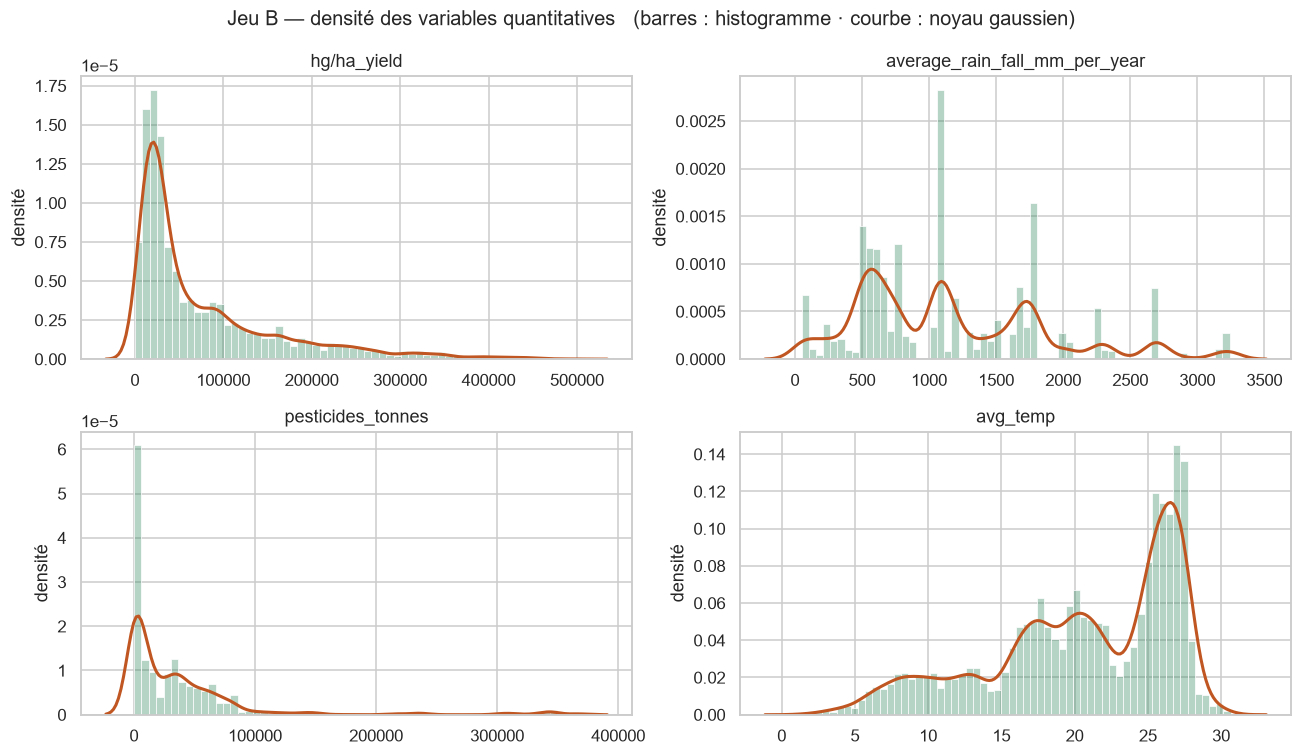

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, NUMERIC_B):
    sns.histplot(yield_df[col], bins=60, stat='density', ax=ax,
                 color=GREEN, alpha=0.35, edgecolor=None)
    sns.kdeplot(yield_df[col], ax=ax, color=ORANGE, linewidth=2)
    ax.set(title=col, xlabel='', ylabel='densité')

fig.suptitle('Jeu B — densité des variables quantitatives   '
             '(barres : histogramme · courbe : noyau gaussien)', fontsize=13)
fig.tight_layout()
plt.show()

> **Observation.** Distributions **fortement asymétriques**, à longue traîne — quelques pays concentrent les rendements et les volumes de pesticides les plus élevés. Seule `avg_temp` approche la symétrie. La courbe lissée déborde ici dans les valeurs négatives : même limite que pour le jeu A.

In [23]:
# Conversion hg/ha -> t/ha pour comparer les deux jeux dans la meme unite
yield_by_crop = yield_df.groupby('Item')['hg/ha_yield'].agg(['mean', 'median', 'count'])
yield_by_crop[['mean', 'median']] /= HG_PER_HA_TO_T_PER_HA
yield_by_crop = yield_by_crop.sort_values('median', ascending=False)
yield_by_crop

,mean,median,count
Item,,,
Potatoes,19.980,18.227,4276
Cassava,15.048,12.820,2045
Sweet potatoes,11.906,9.994,2890
Yams,11.414,9.259,847
Plantains and others,10.604,8.986,556
"Rice, paddy",4.073,3.588,3388
Wheat,3.012,2.550,3857
Maize,3.631,2.540,4121
Soybeans,1.673,1.553,3223


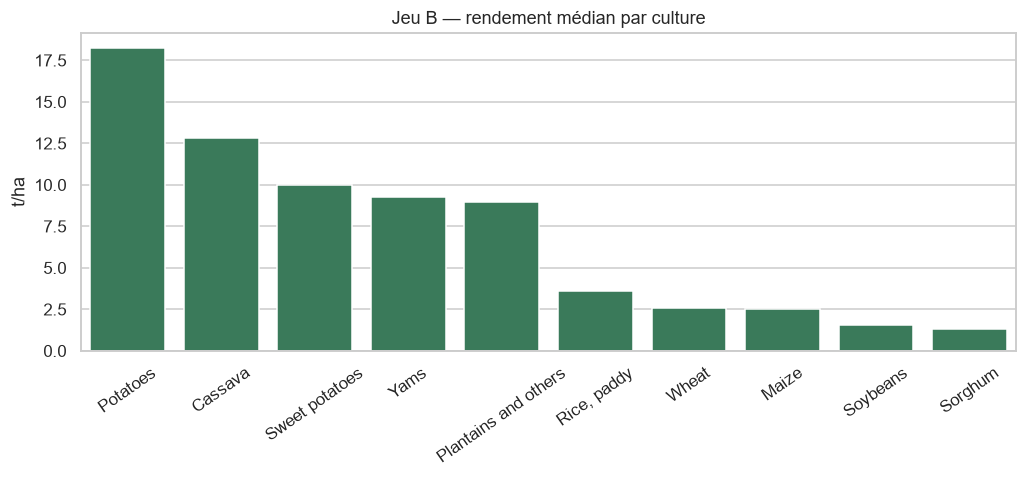

In [24]:
plot_df = yield_by_crop.reset_index()

fig, ax = plt.subplots(figsize=(9.5, 4.5))
sns.barplot(data=plot_df, x='Item', y='median', ax=ax, color=GREEN)
ax.set(title='Jeu B — rendement médian par culture', xlabel='', ylabel='t/ha')
ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
plt.show()

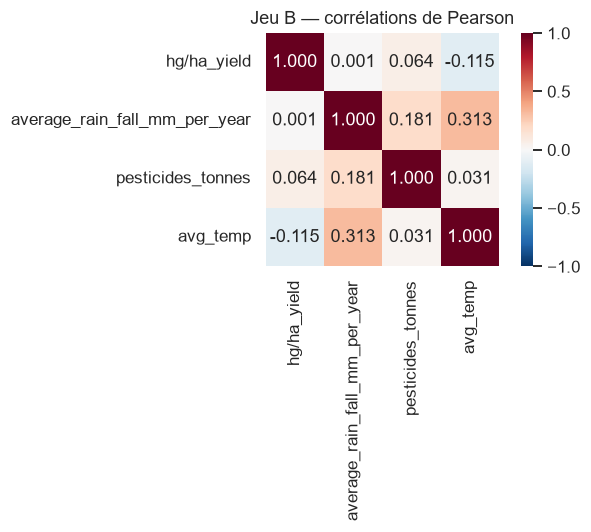

In [25]:
corr_b = yield_df[NUMERIC_B].corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr_b, annot=True, fmt='.3f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Jeu B — corrélations de Pearson')
fig.tight_layout()
plt.show()

> **Observation.** Contrairement au jeu A, le jeu B **différencie fortement les cultures** — plus d'un facteur 10 entre extrêmes. C'est l'information qui manque au jeu A, et la raison de recourir à une source FAO. Reste à choisir **laquelle** : voir section 8.

### 3.3 Variables *proxy* d'intensification agricole

Le jeu A ne décrit les pratiques que par **deux booléens**, sans notion d'intensité. Le jeu B porte `pesticides_tonnes`, une mesure continue. Peut-elle servir de *proxy* transférable ?

In [26]:
# Intensite reelle ou simple volume national ? Les extremes repondent
pest_by_country = yield_df.groupby('Area')['pesticides_tonnes'].max().sort_values(ascending=False)

print('Correlation pesticides_tonnes ~ rendement :',
      round(yield_df['pesticides_tonnes'].corr(yield_df['hg/ha_yield']), 4))
print()
print('Plus gros volumes nationaux (tonnes) :')
print(pest_by_country.head(5))
print()
print('Plus faibles volumes nationaux (tonnes) :')
print(pest_by_country.tail(5))

Correlation pesticides_tonnes ~ rendement : 0.0641

Plus gros volumes nationaux (tonnes) :
Area
Brazil      367,778.000
Argentina   171,945.540
Colombia    117,881.450
France      114,695.000
Italy       100,596.400
Name: pesticides_tonnes, dtype: float64

Plus faibles volumes nationaux (tonnes) :
Area
Eritrea                    30.920
Bahrain                    30.860
Haiti                      27.850
Central African Republic   22.870
Botswana                   19.000
Name: pesticides_tonnes, dtype: float64


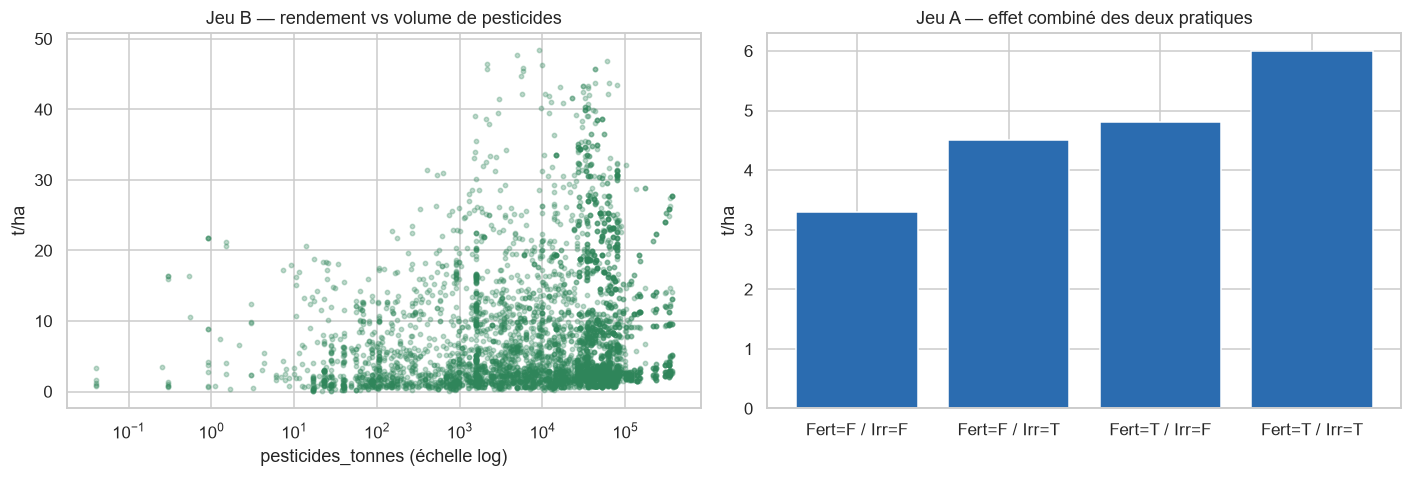

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sample_b = yield_df.sample(5_000, random_state=RANDOM_STATE)
axes[0].scatter(sample_b['pesticides_tonnes'], sample_b['hg/ha_yield'] / HG_PER_HA_TO_T_PER_HA,
                s=8, alpha=0.3, color=GREEN)
axes[0].set(xscale='log', xlabel='pesticides_tonnes (échelle log)', ylabel='t/ha',
            title='Jeu B — rendement vs volume de pesticides')

practice = crop_yield.groupby(BOOLEAN_FEATURES, observed=True)[TARGET].mean().reset_index()
labels = ['Fert=' + str(f)[0] + ' / Irr=' + str(i)[0]
          for f, i in zip(practice['Fertilizer_Used'], practice['Irrigation_Used'])]
axes[1].bar(labels, practice[TARGET], color=BLUE)
axes[1].set(ylabel='t/ha', title='Jeu A — effet combiné des deux pratiques')

fig.tight_layout()
plt.show()

> **Conclusion.** `pesticides_tonnes` est un **volume national absolu**, non rapporté à la surface : les plus grandes valeurs sont celles des plus grands pays agricoles, et la corrélation au rendement est quasi nulle (0,064).
>
> **Ce n'est pas un proxy valable** d'intensification à la parcelle — il faudrait le normaliser par la surface cultivée, absente des deux jeux. **Décision** : garder `Fertilizer_Used` et `Irrigation_Used` comme seuls descripteurs des pratiques.

## 4. `yield.csv` — source FAO brute

Rendements FAO par pays, culture et année. C'est la **colonne vertébrale** du jeu B : les trois autres sources viennent s'y greffer.

In [28]:
fao_yield = pd.read_csv(YIELD_RAW_PATH)

print(format(fao_yield.shape[0], ',d'), 'lignes x', fao_yield.shape[1], 'colonnes')
fao_yield.head()

56,717 lignes x 12 colonnes


,Domain Code,Domain,Area Code,Area,Element Code,Element,Item Code,Item,Year Code,Year,Unit,Value
0,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1961,1961,hg/ha,14000
1,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1962,1962,hg/ha,14000
2,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1963,1963,hg/ha,14260
3,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1964,1964,hg/ha,14257
4,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1965,1965,hg/ha,14400


In [29]:
summarize(fao_yield, 'yield.csv — rendements FAO')
print()
profile_dataframe(fao_yield)

yield.csv — rendements FAO
  dimensions          : 56,717 lignes x 12 colonnes
  memoire             : 20.4 Mo
  cellules manquantes : 0 (0.0000 % du total)
  colonnes avec NaN   : 0 sur 12
  lignes dupliquees   : 0



,type,non_nuls,nan,nan_pct,uniques,uniques_pct,memoire_mo,exemple
Domain Code,str,56717,0,0.000,1,0.000,2.760,QC
Domain,str,56717,0,0.000,1,0.000,2.920,Crops
Area Code,int64,56717,0,0.000,212,0.370,0.430,2
Area,str,56717,0,0.000,212,0.370,3.230,Afghanistan
Element Code,int64,56717,0,0.000,1,0.000,0.430,5419
Element,str,56717,0,0.000,1,0.000,2.920,Yield
Item Code,int64,56717,0,0.000,10,0.020,0.430,56
Item,str,56717,0,0.000,10,0.020,3.100,Maize
Year Code,int64,56717,0,0.000,56,0.100,0.430,1961
Year,int64,56717,0,0.000,56,0.100,0.430,1961


In [30]:
# Qualite structurelle : colonnes sans information, et codes redondants avec leur libelle
print('Colonnes constantes :', constant_columns(fao_yield))
print('Year identique a Year Code ?', bool((fao_yield['Year'] == fao_yield['Year Code']).all()))
print('Area Code <-> Area  :', fao_yield['Area Code'].nunique(), 'vs', fao_yield['Area'].nunique())
print('Item Code <-> Item  :', fao_yield['Item Code'].nunique(), 'vs', fao_yield['Item'].nunique())
print()
display(duplicate_report(fao_yield, ['Area', 'Item', 'Year']).to_frame())

print('Pays     :', fao_yield['Area'].nunique())
print('Cultures :', fao_yield['Item'].nunique())
print('Annees   :', fao_yield['Year'].min(), '-', fao_yield['Year'].max())
fao_yield['Value'].describe().to_frame('Value (hg/ha)').T

Colonnes constantes : ['Domain Code', 'Domain', 'Element Code', 'Element', 'Unit']
Year identique a Year Code ? True


Area Code <-> Area  : 212 vs 212
Item Code <-> Item  : 10 vs 10



,doublons
lignes,56717
doublons_stricts,0
doublons_sur_cle,0
lignes_impliquees,0
cles_uniques,56717


Pays     : 212
Cultures : 10
Annees   : 1961 - 2016


,count,mean,std,min,25%,50%,75%,max
Value (hg/ha),"56,717.000","62,094.660","67,835.933",0.000,"15,680.000","36,744.000","86,213.000","1,000,000.000"


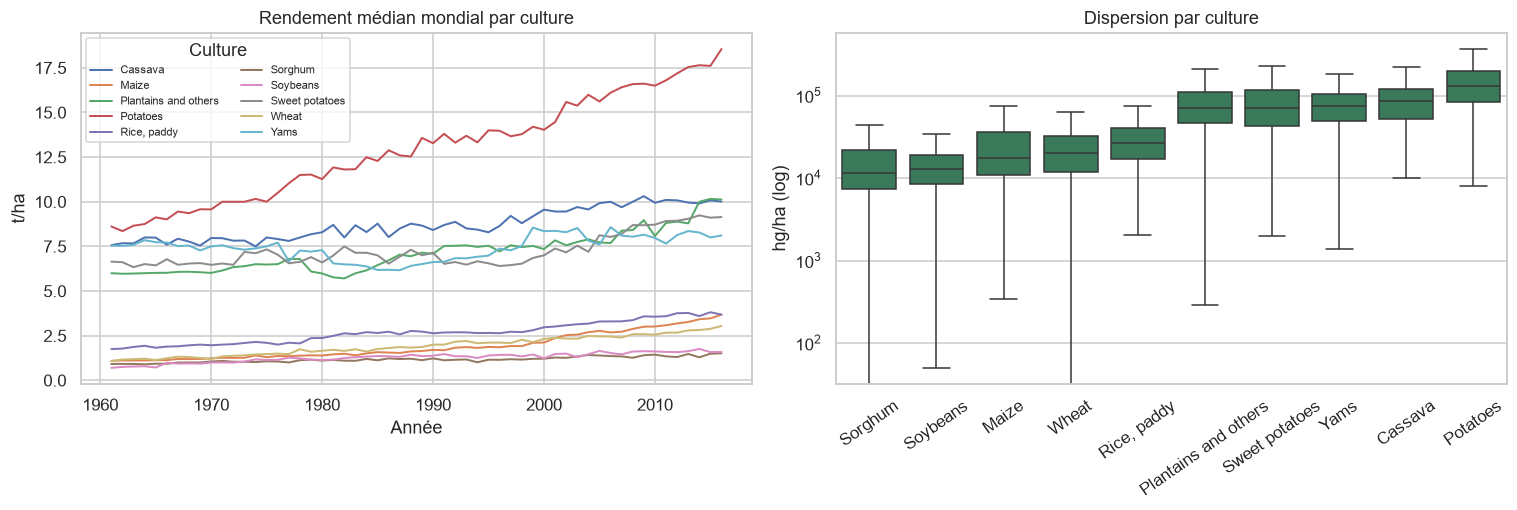

In [31]:
# Evolution historique : le rendement progresse-t-il, et de la meme facon selon les cultures ?
evolution = (fao_yield.assign(t_ha=fao_yield['Value'] / HG_PER_HA_TO_T_PER_HA)
             .groupby(['Year', 'Item'])['t_ha'].median().unstack())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
evolution.plot(ax=axes[0], linewidth=1.3)
axes[0].set(title='Rendement médian mondial par culture', xlabel='Année', ylabel='t/ha')
axes[0].legend(title='Culture', fontsize=7, ncol=2)

order = fao_yield.groupby('Item')['Value'].median().sort_values().index
sns.boxplot(data=fao_yield, x='Item', y='Value', order=order,
            ax=axes[1], color=GREEN, showfliers=False)
axes[1].set(yscale='log', title='Dispersion par culture', xlabel='', ylabel='hg/ha (log)')
axes[1].tick_params(axis='x', rotation=35)

fig.tight_layout()
plt.show()

> **Observation.** Fichier **propre** : aucun doublon sur `(Area, Item, Year)`, aucune valeur manquante, 212 pays, 1961-2016.
>
> Mais **5 colonnes sur 12 sont constantes** et `Year` duplique `Year Code` ; `Area Code` et `Item Code` sont en bijection avec leurs libellés. **Seules 4 colonnes informent** : `Area`, `Item`, `Year`, `Value`.
>
> La progression historique des rendements est nette et contrastée selon les cultures : un signal réel, absent du jeu A simulé.

## 5. `pesticides.csv` — source brute

Usage de pesticides déclaré à la FAO, en tonnes de matière active, par pays et par année.

In [32]:
pesticides = pd.read_csv(PESTICIDES_PATH)

print(format(pesticides.shape[0], ',d'), 'lignes x', pesticides.shape[1], 'colonnes')
pesticides.head()

4,349 lignes x 7 colonnes


,Domain,Area,Element,Item,Year,Unit,Value
0,Pesticides Use,Albania,Use,Pesticides (total),1990,tonnes of active ingredients,121.000
1,Pesticides Use,Albania,Use,Pesticides (total),1991,tonnes of active ingredients,121.000
2,Pesticides Use,Albania,Use,Pesticides (total),1992,tonnes of active ingredients,121.000
3,Pesticides Use,Albania,Use,Pesticides (total),1993,tonnes of active ingredients,121.000
4,Pesticides Use,Albania,Use,Pesticides (total),1994,tonnes of active ingredients,201.000


In [33]:
summarize(pesticides, 'pesticides.csv')
print()
profile_dataframe(pesticides)

pesticides.csv
  dimensions          : 4,349 lignes x 7 colonnes
  memoire             : 1.4 Mo
  cellules manquantes : 0 (0.0000 % du total)
  colonnes avec NaN   : 0 sur 7
  lignes dupliquees   : 0



,type,non_nuls,nan,nan_pct,uniques,uniques_pct,memoire_mo,exemple
Domain,str,4349,0,0.000,1,0.020,0.260,Pesticides Use
Area,str,4349,0,0.000,168,3.860,0.240,Albania
Element,str,4349,0,0.000,1,0.020,0.220,Use
Item,str,4349,0,0.000,1,0.020,0.280,Pesticides (total)
Year,int64,4349,0,0.000,27,0.620,0.030,1990
Unit,str,4349,0,0.000,1,0.020,0.320,tonnes of active ingredients
Value,float64,4349,0,0.000,2825,64.960,0.030,121.000


In [34]:
print('Colonnes constantes :', constant_columns(pesticides))
print()
display(duplicate_report(pesticides, ['Area', 'Year']).to_frame())

print('Pays   :', pesticides['Area'].nunique())
print('Annees :', pesticides['Year'].min(), '-', pesticides['Year'].max())
pesticides['Value'].describe().to_frame('Value (tonnes)').T

Colonnes constantes : ['Domain', 'Element', 'Item', 'Unit']



,doublons
lignes,4349
doublons_stricts,0
doublons_sur_cle,0
lignes_impliquees,0
cles_uniques,4349


Pays   : 168
Annees : 1990 - 2016


,count,mean,std,min,25%,50%,75%,max
Value (tonnes),"4,349.000","20,303.341","117,736.190",0.000,93.000,"1,137.560","7,869.000","1,807,000.000"


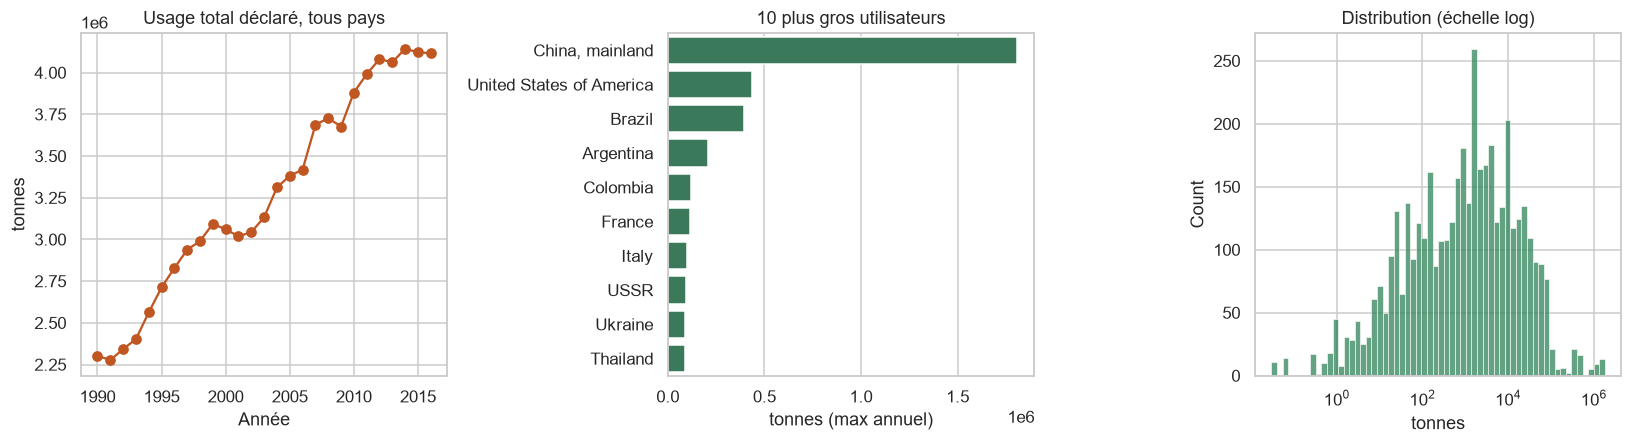

In [35]:
world_use = pesticides.groupby('Year')['Value'].sum()
top_users = pesticides.groupby('Area')['Value'].max().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(world_use.index, world_use.to_numpy(), marker='o', color=ORANGE)
axes[0].set(title='Usage total déclaré, tous pays', xlabel='Année', ylabel='tonnes')

sns.barplot(x=top_users.to_numpy(), y=top_users.index, ax=axes[1], color=GREEN)
axes[1].set(title='10 plus gros utilisateurs', xlabel='tonnes (max annuel)', ylabel='')

sns.histplot(pesticides['Value'], bins=60, log_scale=True, ax=axes[2], color=GREEN)
axes[2].set(title='Distribution (échelle log)', xlabel='tonnes')

fig.tight_layout()
plt.show()

> **Observation.** Fichier propre — aucun doublon sur `(Area, Year)`, aucune valeur manquante — mais **4 colonnes sur 7 sont constantes** : seules `Area`, `Year` et `Value` informent.
>
> Distribution **extrêmement asymétrique**, d'où l'échelle logarithmique. Surtout, la variable est un **volume national**, pas une intensité par hectare. Couverture limitée : **168 pays, à partir de 1990** — ce qui amputera la fusion.

## 6. `rainfall.csv` — source brute

Pluviométrie annuelle moyenne par pays. Ce fichier concentre le plus de pièges de lecture.

In [36]:
rainfall = pd.read_csv(RAINFALL_PATH)

print('Noms de colonnes bruts :', [repr(c) for c in rainfall.columns])
rainfall.head()

Noms de colonnes bruts : ["' Area'", "'Year'", "'average_rain_fall_mm_per_year'"]


,Area,Year,average_rain_fall_mm_per_year
0,Afghanistan,1985,327
1,Afghanistan,1986,327
2,Afghanistan,1987,327
3,Afghanistan,1989,327
4,Afghanistan,1990,327


In [37]:
# Piege 1 : la colonne pays porte un espace initial -> nettoyage des en-tetes
rainfall.columns = [col.strip() for col in rainfall.columns]

# Piege 2 : la pluviometrie est typee texte ; on mesure ce que la conversion perdrait
rain_col = 'average_rain_fall_mm_per_year'
rainfall['rain_mm'] = pd.to_numeric(rainfall[rain_col], errors='coerce')

summarize(rainfall, 'rainfall.csv')
print()
display(profile_dataframe(rainfall))

non_numeric = rainfall['rain_mm'].isna().sum()
print('Valeurs non convertibles en nombre :', format(non_numeric, ',d'),
      '(' + format(100 * non_numeric / len(rainfall), '.1f') + ' %)')
print('Pays   :', rainfall['Area'].nunique())
print('Annees :', rainfall['Year'].min(), '-', rainfall['Year'].max())

rainfall.csv
  dimensions          : 6,727 lignes x 4 colonnes
  memoire             : 0.8 Mo
  cellules manquantes : 1,554 (5.7752 % du total)
  colonnes avec NaN   : 2 sur 4
  lignes dupliquees   : 0



,type,non_nuls,nan,nan_pct,uniques,uniques_pct,memoire_mo,exemple
Area,str,6727,0,0.000,217,3.230,0.370,Afghanistan
Year,int64,6727,0,0.000,31,0.460,0.050,1985
average_rain_fall_mm_per_year,str,5953,774,11.510,173,2.570,0.320,327
rain_mm,float64,5947,780,11.600,172,2.560,0.050,327.000


Valeurs non convertibles en nombre : 780 (11.6 %)
Pays   : 217
Annees : 1985 - 2017


In [38]:
# Piege 3 : la pluviometrie varie-t-elle vraiment d'une annee a l'autre ?
distinct_per_country = rainfall.groupby('Area')['rain_mm'].nunique(dropna=True)
constant_countries = int((distinct_per_country <= 1).sum())

print('Pays avec une seule valeur de pluie sur toute la periode :',
      constant_countries, '/', distinct_per_country.size)
print('Soit', format(100 * constant_countries / distinct_per_country.size, '.1f'), '% des pays')
print()
print('Exemple — Afghanistan :', rainfall.loc[rainfall['Area'] == 'Afghanistan', 'rain_mm'].dropna().unique())
display(duplicate_report(rainfall, ['Area', 'Year']).to_frame())

Pays avec une seule valeur de pluie sur toute la periode : 213 / 217
Soit 98.2 % des pays

Exemple — Afghanistan : [327.]


,doublons
lignes,6727
doublons_stricts,0
doublons_sur_cle,0
lignes_impliquees,0
cles_uniques,6727


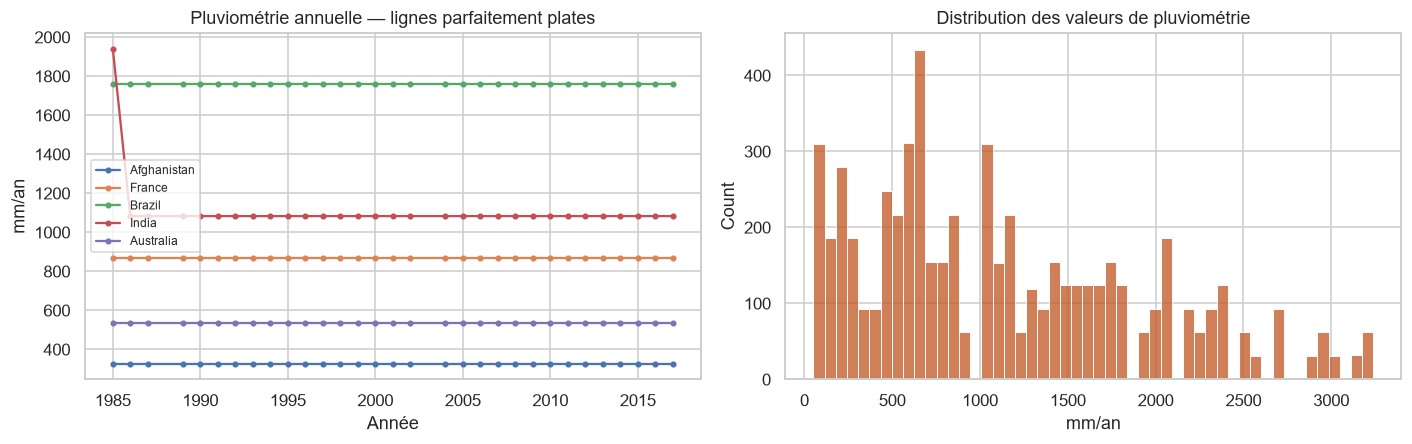

In [39]:
wanted = ['Afghanistan', 'France', 'Brazil', 'India', 'Australia']
shown = [c for c in wanted if c in set(rainfall['Area'])] or sorted(rainfall['Area'].unique())[:5]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for country in shown:
    sub = rainfall[rainfall['Area'] == country].sort_values('Year')
    axes[0].plot(sub['Year'], sub['rain_mm'], marker='.', label=country)
axes[0].set(title='Pluviométrie annuelle — lignes parfaitement plates',
            xlabel='Année', ylabel='mm/an')
axes[0].legend(fontsize=8)

sns.histplot(rainfall['rain_mm'].dropna(), bins=50, ax=axes[1], color=ORANGE)
axes[1].set(title='Distribution des valeurs de pluviométrie', xlabel='mm/an')

fig.tight_layout()
plt.show()

> **Observation — la découverte majeure.** `average_rain_fall_mm_per_year` **ne varie pas dans le temps** : **213 pays sur 217** n'ont qu'une seule valeur sur 1985-2017 (Afghanistan : 327 mm chaque année).
>
> Ce n'est donc pas une mesure annuelle mais une **normale climatique par pays**. Dans le jeu B, cette variable est une **constante par pays** : un modèle qui l'utilise apprend à reconnaître le pays, pas le climat.
>
> S'y ajoutent deux pièges : le nom de colonne ` Area` avec **espace initial**, et un typage **texte** masquant **780 valeurs non convertibles (11,6 %)**.

## 7. `temp.csv` — source brute

Températures moyennes par pays et par année. C'est ce fichier qui explique les doublons du jeu B.

In [40]:
temperatures = pd.read_csv(TEMP_PATH)

print(format(temperatures.shape[0], ',d'), 'lignes x', temperatures.shape[1], 'colonnes')
temperatures.head()

71,311 lignes x 3 colonnes


,year,country,avg_temp
0,1849,Côte D'Ivoire,25.580
1,1850,Côte D'Ivoire,25.520
2,1851,Côte D'Ivoire,25.670
3,1852,Côte D'Ivoire,NaN
4,1853,Côte D'Ivoire,NaN


In [41]:
summarize(temperatures, 'temp.csv')
print()
display(profile_dataframe(temperatures))

print('Pays   :', temperatures['country'].nunique())
print('Annees :', temperatures['year'].min(), '-', temperatures['year'].max())
display(duplicate_report(temperatures, ['country', 'year']).to_frame())

temp.csv
  dimensions          : 71,311 lignes x 3 colonnes
  memoire             : 5.0 Mo
  cellules manquantes : 2,547 (1.1906 % du total)
  colonnes avec NaN   : 1 sur 3
  lignes dupliquees   : 6,958



,type,non_nuls,nan,nan_pct,uniques,uniques_pct,memoire_mo,exemple
year,int64,71311,0,0.000,271,0.380,0.540,1849
country,str,71311,0,0.000,137,0.190,3.910,Côte D'Ivoire
avg_temp,float64,68764,2547,3.570,3303,4.630,0.540,25.580


Pays   : 137
Annees : 1743 - 2013


,doublons
lignes,71311
doublons_stricts,6958
doublons_sur_cle,42797
lignes_impliquees,50791
cles_uniques,28514


In [42]:
# Les releves multiples portent-ils la meme valeur, ou des valeurs differentes ?
grouped = temperatures.groupby(['country', 'year'])['avg_temp']
sizes, distinct = grouped.size(), grouped.nunique()
spread = (grouped.max() - grouped.min())

multiple = sizes > 1
print('Couples (pays, annee)            :', format(len(sizes), ',d'))
print('  avec plusieurs releves         :', format(int(multiple.sum()), ',d'))
print('    dont valeurs identiques      :', format(int((multiple & (distinct == 1)).sum()), ',d'))
print('    dont valeurs DIFFERENTES     :', format(int((distinct > 1).sum()), ',d'))
print()
print('Ecart intra-couple : moyenne', round(spread.mean(), 2), 'C | maximum', round(spread.max(), 2), 'C')
spread.sort_values(ascending=False).head(5).to_frame('ecart_C')

Couples (pays, annee)            : 28,514
  avec plusieurs releves         : 7,994
    dont valeurs identiques      : 307
    dont valeurs DIFFERENTES     : 7,534

Ecart intra-couple : moyenne 1.3 C | maximum 27.95 C


ecart_C
country       year         
United States 1760   27.950
              1848   23.650
              1839   22.240
              1745   22.190
China         1915   21.170

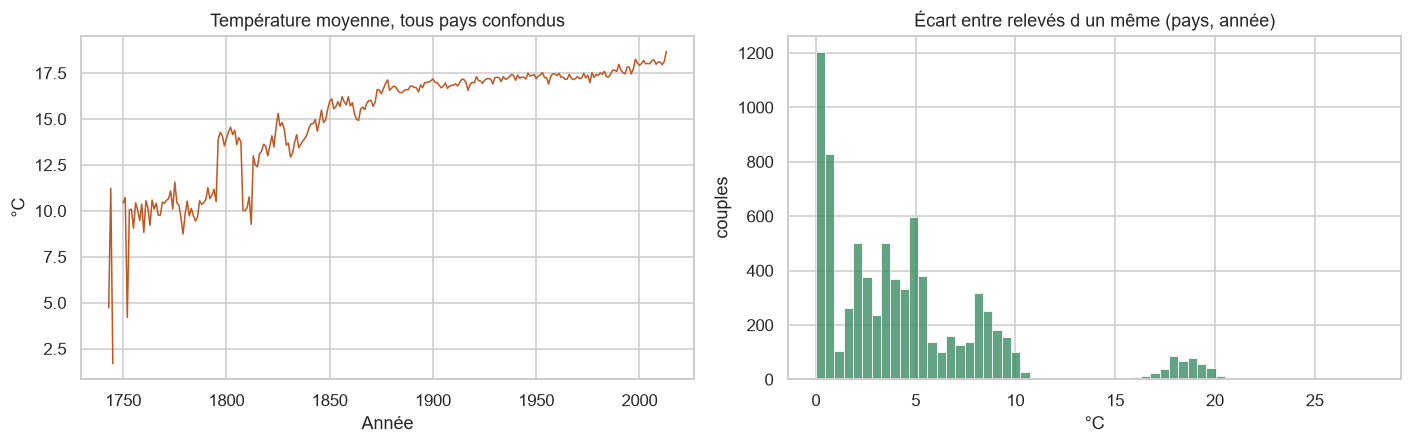

In [43]:
world_temp = temperatures.groupby('year')['avg_temp'].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(world_temp.index, world_temp.to_numpy(), color=ORANGE, linewidth=1)
axes[0].set(title='Température moyenne, tous pays confondus', xlabel='Année', ylabel='°C')

sns.histplot(spread[multiple], bins=60, ax=axes[1], color=GREEN)
axes[1].set(title='Écart entre relevés d un même (pays, année)', xlabel='°C', ylabel='couples')

fig.tight_layout()
plt.show()

> **Observation.** Source des anomalies du jeu B : sur 28 514 couples `(pays, année)`, **7 994 ont plusieurs relevés**, dont **7 534 à valeurs différentes** — écart moyen 1,3 °C, maximum 27,9 °C.
>
> Le fichier ne documente pas leur nature : ni station, ni ville, ni région. L'hypothèse de relevés **infranationaux** est la seule compatible, mais elle reste une hypothèse. Ce sont donc des mesures à **agréger**, pas des doublons à supprimer — la médiane étant préférable à la moyenne.
>
> Couverture géographique la plus étroite des quatre sources : **137 pays**.

## 8. Reconstitution du jeu B et choix de la source

`yield_df.csv` est-il bien la jointure des quatre sources ? On la rejoue et on compare ligne à ligne — puis on en tire une décision sur la source à utiliser.

In [44]:
# Reconstitution de la recette : jointures internes successives sur (Area, Year)
fao = fao_yield[['Area', 'Item', 'Year', 'Value']].rename(columns={'Value': 'hg/ha_yield'})
rain = rainfall[['Area', 'Year', 'rain_mm']].rename(columns={'rain_mm': 'average_rain_fall_mm_per_year'})
pest = pesticides[['Area', 'Year', 'Value']].rename(columns={'Value': 'pesticides_tonnes'})
temp = temperatures.rename(columns={'year': 'Year', 'country': 'Area'})

KEY = ['Area', 'Item', 'Year']
steps = [('yield.csv seul', fao)]
step = fao.merge(rain, on=['Area', 'Year']);  steps.append(('  x rainfall', step))
step = step.merge(pest, on=['Area', 'Year']); steps.append(('  x pesticides', step))
step = step.merge(temp, on=['Area', 'Year']); steps.append(('  x temp', step))

trace = pd.DataFrame(
    [{'etape': name, 'lignes': len(d), 'cles_uniques': d.drop_duplicates(subset=KEY).shape[0]}
     for name, d in steps]
    + [{'etape': 'yield_df.csv fourni', 'lignes': len(yield_df),
        'cles_uniques': yield_df.drop_duplicates(subset=KEY).shape[0]}]
).set_index('etape')
trace

,lignes,cles_uniques
etape,,
yield.csv seul,56717,56717
x rainfall,26105,26105
x pesticides,19356,19356
x temp,28248,13136
yield_df.csv fourni,28242,13130


In [45]:
# Comparaison ligne a ligne entre reconstitution et fichier fourni
from collections import Counter

rebuilt = step[list(yield_df.columns)]

def row_counter(frame):
    tmp = frame.copy()
    for col in NUMERIC_B:
        tmp[col] = pd.to_numeric(tmp[col]).round(3)
    return Counter(map(tuple, tmp.to_numpy().tolist()))

extra = row_counter(rebuilt) - row_counter(yield_df)
missing = row_counter(yield_df) - row_counter(rebuilt)

print('Lignes presentes dans la reconstitution seulement :', sum(extra.values()))
print('Lignes presentes dans yield_df.csv seulement      :', sum(missing.values()))
print()
for row, n in extra.items():
    print(' +', n, row)

Lignes presentes dans la reconstitution seulement : 6
Lignes presentes dans yield_df.csv seulement      : 0

 + 1 ('Bahamas', 'Cassava', 1990, 106667, nan, 484.59, 25.74)
 + 1 ('Bahamas', 'Cassava', 1991, 100000, nan, 484.59, 25.66)
 + 1 ('Bahamas', 'Maize', 1990, 15000, nan, 484.59, 25.74)
 + 1 ('Bahamas', 'Maize', 1991, 16667, nan, 484.59, 25.66)
 + 1 ('Bahamas', 'Sweet potatoes', 1990, 38118, nan, 484.59, 25.74)
 + 1 ('Bahamas', 'Sweet potatoes', 1991, 31385, nan, 484.59, 25.66)


In [46]:
# Perte et inflation, exprimees en proportion
initial, final_rows = len(fao), len(yield_df)
final_keys = yield_df.drop_duplicates(subset=KEY).shape[0]

print('Observations FAO au depart       :', format(initial, ',d'))
print('Observations reellement retenues :', format(final_keys, ',d'),
      '(' + format(100 * final_keys / initial, '.1f') + ' % conservees)')
print('Lignes du fichier livre          :', format(final_rows, ',d'),
      '-> facteur de duplication x' + format(final_rows / final_keys, '.2f'))
print()
print('Pays : yield.csv', fao['Area'].nunique(), '| rainfall', rain['Area'].nunique(),
      '| pesticides', pest['Area'].nunique(), '| temp', temp['Area'].nunique(),
      '-> yield_df', yield_df['Area'].nunique())

Observations FAO au depart       : 56,717
Observations reellement retenues : 13,130 (23.2 % conservees)
Lignes du fichier livre          : 28,242 -> facteur de duplication x2.15

Pays : yield.csv 212 | rainfall 217 | pesticides 168 | temp 137 -> yield_df 101


In [47]:
# Le gonflement est-il uniforme entre pays ? C'est ce qui decide
# si une moyenne non dedoublonnee est biaisee, et dans quelle mesure.
lignes_par_pays = yield_df.groupby('Area').size().rename('lignes')
cles_par_pays = yield_df.drop_duplicates(subset=KEY).groupby('Area').size().rename('cles')

duplication = pd.concat([lignes_par_pays, cles_par_pays], axis=1)
duplication['facteur'] = (duplication['lignes'] / duplication['cles']).round(2)
duplication['part_des_lignes_pct'] = (100 * duplication['lignes'] / len(yield_df)).round(2)
duplication['part_des_cles_pct'] = (100 * duplication['cles'] / cles_par_pays.sum()).round(2)

print('Pays non dupliques (facteur = 1) :',
      int((duplication['facteur'] == 1).sum()), 'sur', len(duplication))
print('Facteur median :', duplication['facteur'].median(),
      '| moyen :', round(duplication['facteur'].mean(), 2),
      '| maximum :', duplication['facteur'].max())
print()
duplication.sort_values('facteur', ascending=False).head(6)

Pays non dupliques (facteur = 1) : 74 sur 101
Facteur median : 1.0 | moyen : 1.95 | maximum : 22.0



,lignes,cles,facteur,part_des_lignes_pct,part_des_cles_pct
Area,,,,,
India,4048,184,22.000,14.330,1.400
Brazil,2277,207,11.000,8.060,1.580
Pakistan,1449,161,9.000,5.130,1.230
Mexico,1472,184,8.000,5.210,1.400
Australia,966,161,6.000,3.420,1.230
Japan,966,161,6.000,3.420,1.230


In [48]:
# D'ou vient la perte ? La cible n'est jamais manquante : ce sont les cles qui ne s'apparient pas
print('Valeurs manquantes dans la cible de yield.csv :', int(fao['hg/ha_yield'].isna().sum()))

n0 = len(fao)
debut_pluie = rain['Year'].min()
hors_plage = int((fao['Year'] < debut_pluie).sum())
apres_rain = fao.merge(rain, on=['Area', 'Year'])
apres_pest = apres_rain.merge(pest, on=['Area', 'Year'])
cles_finales = apres_pest.merge(temp, on=['Area', 'Year']).drop_duplicates(subset=KEY).shape[0]

causes = pd.DataFrame([
    (f'Annees anterieures a {debut_pluie} (hors plage de rainfall)', hors_plage),
    ('Pays non apparies avec rainfall', n0 - hors_plage - len(apres_rain)),
    ('Jointure pesticides (1990-2016, 168 pays)', len(apres_rain) - len(apres_pest)),
    ('Jointure temp (jusqu a 2013, 137 pays)', len(apres_pest) - cles_finales),
], columns=['cause', 'observations_perdues']).set_index('cause')
causes['part_pct'] = (100 * causes['observations_perdues'] / n0).round(1)
causes

Valeurs manquantes dans la cible de yield.csv : 0


,observations_perdues,part_pct
cause,,
Annees anterieures a 1985 (hors plage de rainfall),22485,39.600
Pays non apparies avec rainfall,8127,14.300
"Jointure pesticides (1990-2016, 168 pays)",6749,11.900
"Jointure temp (jusqu a 2013, 137 pays)",6220,11.000


In [49]:
# Pour notre besoin reel - un indice par culture - quelle source vaut mieux ?
cultures_communes = list(CROP_MAPPING.values())
depuis_brut = fao_yield[fao_yield['Item'].isin(cultures_communes)]
depuis_fusion = yield_df[yield_df['Item'].isin(cultures_communes)].drop_duplicates(subset=KEY)

couverture = pd.DataFrame({
    'yield.csv (brut)': [len(depuis_brut), depuis_brut['Area'].nunique(),
                         f"{depuis_brut['Year'].min()}-{depuis_brut['Year'].max()}"],
    'yield_df.csv (dedoublonne)': [len(depuis_fusion), depuis_fusion['Area'].nunique(),
                                   f"{depuis_fusion['Year'].min()}-{depuis_fusion['Year'].max()}"],
}, index=['observations', 'pays', 'periode'])
display(couverture)

# L'indice de productivite par culture depend-il de la source retenue ?
indice_brut = depuis_brut.groupby('Item')['Value'].median() / depuis_brut['Value'].median()
indice_fusion = (depuis_fusion.groupby('Item')['hg/ha_yield'].median()
                 / depuis_fusion['hg/ha_yield'].median())

indices = pd.DataFrame({'depuis_yield_csv': indice_brut.round(3),
                        'depuis_yield_df': indice_fusion.round(3)})
indices['ecart_pct'] = (100 * (indices['depuis_yield_df'] / indices['depuis_yield_csv'] - 1)).round(1)
indices

,yield.csv (brut),yield_df.csv (dedoublonne)
observations,25452,6582
pays,195,100
periode,1961-2016,1990-2013


,depuis_yield_csv,depuis_yield_df,ecart_pct
Item,,,
Maize,0.918,1.024,11.500
"Rice, paddy",1.387,1.403,1.200
Soybeans,0.686,0.678,-1.200
Wheat,1.056,1.017,-3.700


> **Conclusion — fusion confirmée, fichier doublement dégradé, et une meilleure source disponible.**
>
> **La reconstitution est exacte** : aucune ligne de `yield_df.csv` n'en est absente. Les 6 lignes excédentaires sont les Bahamas 1990-1991, dont la pluviométrie vaut `'..'` — la recette d'origine a appliqué un `dropna`.
>
> | Effet | Mécanisme |
> |---|---|
> | **Amputation** | 56 717 observations ramenées à **13 130** (−76,8 %), couverture de 212 à **101 pays** |
> | **Inflation** | Les relevés multiples de `temp.csv` regonflent ces 13 130 observations à **28 242 lignes** |
>
> La perte ne vient jamais d'une cible manquante — `yield.csv` n'en a aucune — mais de clés non appariées. Première cause : les **années antérieures à 1985**, hors plage de `rainfall.csv`, soit 39,6 %. La fenêtre finale 1990-2013 est l'intersection du début de `pesticides.csv` et de la fin de `temp.csv`.
>
> L'inflation est **très hétérogène** : 74 pays sur 101 ne sont pas dupliqués, l'Inde l'est 22 fois et pèse **14,3 % des lignes pour 1,4 % des observations**.
>
> **Décision — ne pas utiliser `yield_df.csv`.** Pour un indice de productivité par culture, `yield.csv` seul offre **×3,9 observations**, le double de pays et 56 ans au lieu de 24. Le choix n'est pas neutre : l'indice du maïs varie de **11,5 %** d'une source à l'autre.
>
> Trois règles pour la préparation : **agréger avant de joindre**, préférer la **jointure gauche**, et **ne pas sacrifier d'observations** pour une variable peu informative.

## 9. Clés de jointure disponibles

Quelles clés relient réellement le jeu parcellaire au référentiel FAO ?

In [50]:
# Inventaire des colonnes : existe-t-il une cle geographique ou temporelle commune ?
print('Colonnes jeu A :', list(crop_yield.columns))
print()
print('Colonnes jeu B :', list(yield_df.columns))
print()
print('Modalites Region (jeu A) :', sorted(crop_yield['Region'].unique()))
print('Exemples Area (jeu B)    :', sorted(yield_df['Area'].unique())[:8])

Colonnes jeu A : ['Region', 'Soil_Type', 'Crop', 'Rainfall_mm', 'Temperature_Celsius', 'Fertilizer_Used', 'Irrigation_Used', 'Weather_Condition', 'Days_to_Harvest', 'Yield_tons_per_hectare']

Colonnes jeu B : ['Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']

Modalites Region (jeu A) : ['East', 'North', 'South', 'West']
Exemples Area (jeu B)    : ['Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan']


In [51]:
crops_a = set(crop_yield['Crop'].unique())
crops_b = set(yield_df['Item'].unique())

print('Cultures jeu A :', sorted(crops_a))
print()
print('Cultures jeu B :', sorted(crops_b))
print()
print('Correspondance exacte :', sorted(crops_a & crops_b))

Cultures jeu A : ['Barley', 'Cotton', 'Maize', 'Rice', 'Soybean', 'Wheat']

Cultures jeu B : ['Cassava', 'Maize', 'Plantains and others', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Wheat', 'Yams']

Correspondance exacte : ['Maize', 'Wheat']


In [52]:
# CROP_MAPPING est defini en section 1 : il resservira a la preparation des donnees
matched = sorted(CROP_MAPPING)
unmatched = sorted(crops_a - set(CROP_MAPPING))
coverage = crop_yield['Crop'].isin(matched).mean()

print('Cultures appariables         :', matched)
print('Cultures sans correspondance :', unmatched)
print('Couverture des lignes du jeu A :', format(100 * coverage, '.1f'), '%')

Cultures appariables         : ['Maize', 'Rice', 'Soybean', 'Wheat']
Cultures sans correspondance : ['Barley', 'Cotton']
Couverture des lignes du jeu A : 66.7 %


In [53]:
# Comparaison des echelles de rendement, une fois les unites alignees
comparison = pd.DataFrame({'jeu_A_t_ha': crop_yield.groupby('Crop', observed=True)[TARGET].mean()})
comparison['culture_jeu_B'] = comparison.index.map(CROP_MAPPING)
comparison['jeu_B_t_ha'] = comparison['culture_jeu_B'].map(yield_by_crop['median'])
comparison['ecart_relatif'] = (comparison['jeu_B_t_ha'] / comparison['jeu_A_t_ha']).round(2)
comparison

,jeu_A_t_ha,culture_jeu_B,jeu_B_t_ha,ecart_relatif
Crop,,,,
Barley,4.647,NaN,NaN,NaN
Cotton,4.651,NaN,NaN,NaN
Maize,4.641,Maize,2.540,0.550
Rice,4.651,"Rice, paddy",3.588,0.770
Soybean,4.654,Soybeans,1.553,0.330
Wheat,4.653,Wheat,2.550,0.550


> **Observation.** Le jeu A n'a **ni pays ni année** — ses régions sont quatre zones génériques. La **culture est la seule clé exploitable**, et elle ne couvre que **4 cultures sur 6** : `Barley` et `Cotton` sont absents du référentiel FAO, soit **33 % des lignes** du jeu A.
>
> La comparaison des échelles confirme le diagnostic de la section 2 : le jeu A attribue ~4,65 t/ha à **toutes** les cultures, là où la FAO les hiérarchise nettement.

## 10. Analyse en composantes principales

L'ACP répond à une question précise : **certaines variables sont-elles redondantes entre elles**, au point qu'un petit nombre de dimensions synthétiques suffirait à les résumer ?

Deux précisions avant de commencer, car elles conditionnent la lecture des résultats.

**L'ACP est non supervisée** : elle ignore le rendement. Elle ne peut donc pas, à elle seule, désigner les variables qui expliquent la cible — elle dit seulement comment les variables se structurent entre elles. L'identification des variables clés viendra du croisement avec les résultats supervisés des sections 2.3 et 2.4.

**L'ACP exige des variables quantitatives.** Les trois quantitatives et les deux booléennes du jeu A y entrent légitimement — une variable binaire 0/1 a une corrélation bien définie. Les quatre variables purement qualitatives (`Region`, `Soil_Type`, `Crop`, `Weather_Condition`) en sont exclues : leur traitement rigoureux relèverait d'une analyse factorielle de données mixtes. L'exploration ayant montré qu'elles ne portent aucune information, rien n'est perdu.

### 10.1 Variables actives et cible illustrative

In [54]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Variables actives : les quantitatives et les booleennes, qui ont une correlation definie
ACTIVES = NUMERIC_FEATURES + BOOLEAN_FEATURES

# PCA de scikit-learn centre mais NE REDUIT PAS : la standardisation est explicite,
# faute de quoi l'analyse porterait sur les unites plutot que sur les liaisons
X = StandardScaler().fit_transform(crop_yield[ACTIVES].astype(float))

acp = PCA()
composantes = acp.fit_transform(X)

valeurs_propres = pd.DataFrame({
    'valeur_propre': acp.explained_variance_,
    'inertie_%': 100 * acp.explained_variance_ratio_,
    'inertie_cumulée_%': 100 * acp.explained_variance_ratio_.cumsum(),
}, index=[f'F{i}' for i in range(1, len(ACTIVES) + 1)])

print('Variables actives :', ACTIVES)
print('Critère de Kaiser : un axe est retenu si son inertie dépasse',
      round(100 / len(ACTIVES), 1), '%')
valeurs_propres.round(3)

Variables actives : ['Rainfall_mm', 'Temperature_Celsius', 'Days_to_Harvest', 'Fertilizer_Used', 'Irrigation_Used']
Critère de Kaiser : un axe est retenu si son inertie dépasse 20.0 %


,valeur_propre,inertie_%,inertie_cumulée_%
F1,1.003,20.068,20.068
F2,1.003,20.050,40.118
F3,1.001,20.012,60.130
F4,0.997,19.939,80.069
F5,0.997,19.931,100.000


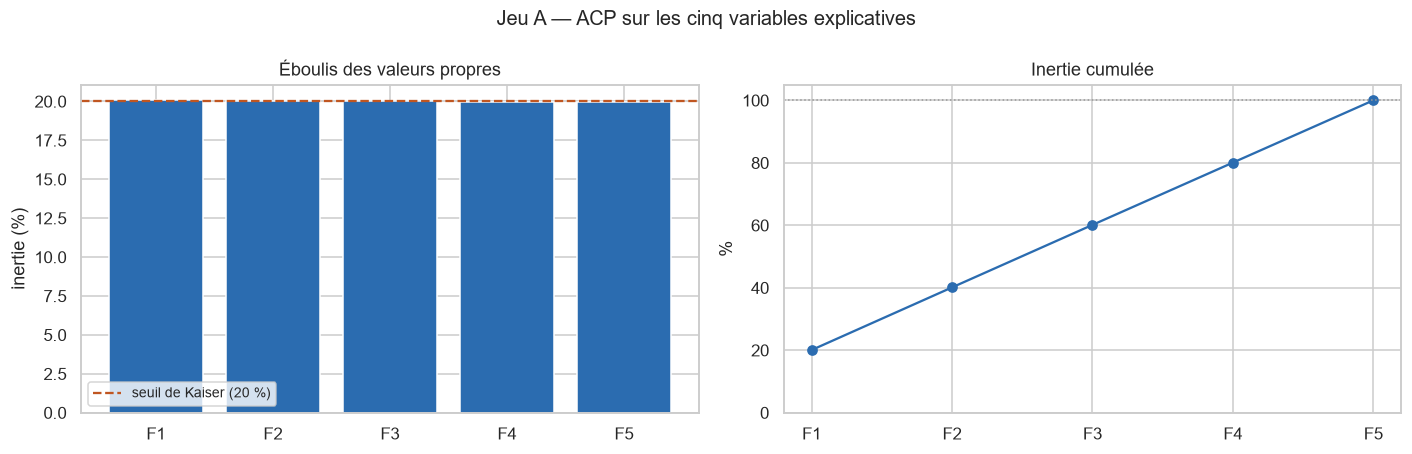

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].bar(valeurs_propres.index, valeurs_propres['inertie_%'], color=BLUE)
axes[0].axhline(100 / len(ACTIVES), color=ORANGE, linestyle='--', linewidth=1.5,
                label=f'seuil de Kaiser ({100 / len(ACTIVES):.0f} %)')
axes[0].set(title='Éboulis des valeurs propres', ylabel='inertie (%)')
axes[0].legend(fontsize=9)

axes[1].plot(valeurs_propres.index, valeurs_propres['inertie_cumulée_%'],
             marker='o', color=BLUE)
axes[1].axhline(100, color='0.6', linestyle=':', linewidth=1)
axes[1].set(title='Inertie cumulée', ylabel='%', ylim=(0, 105))

fig.suptitle('Jeu A — ACP sur les cinq variables explicatives', fontsize=13)
fig.tight_layout()
plt.show()

> **Aucune structure à extraire.** Les cinq valeurs propres valent toutes 1 et chaque axe porte 20 % de l'inertie — exactement ce qu'on obtiendrait avec cinq variables indépendantes. Le critère de Kaiser retient donc tous les axes : aucune réduction n'est pertinente.
>
> C'est une **règle de sélection**, non une frontière entre information et absence d'information. Et quand les valeurs propres sont égales, les axes ne sont **pas identifiables** : les interpréter serait sans fondement.

In [56]:
# Un axe principal est-il stable ? On le reestime sur plusieurs sous-echantillons
# et on mesure l'angle avec l'axe de reference : proche de 0 si l'axe est identifiable.
tirage = np.random.default_rng(RANDOM_STATE)
angles = []
for _ in range(5):
    indices = tirage.choice(len(X), 200_000, replace=False)
    axe = PCA().fit(X[indices]).components_[0]
    cosinus = np.clip(abs(axe @ acp.components_[0]), -1, 1)
    angles.append(np.degrees(np.arccos(cosinus)))

print('Angle du premier axe entre sous-échantillons :')
print('  valeurs :', [round(a, 1) for a in angles], 'degrés')
print('  moyenne :', round(np.mean(angles), 1), 'degrés')
print()
print('Un axe identifiable donnerait un angle proche de 0.')

Angle du premier axe entre sous-échantillons :
  valeurs : [np.float64(33.8), np.float64(81.9), np.float64(12.8), np.float64(64.4), np.float64(11.4)] degrés
  moyenne : 40.9 degrés

Un axe identifiable donnerait un angle proche de 0.


> **La non-identifiabilité est mesurée, pas supposée.** Réestimé sur cinq sous-échantillons de 200 000 parcelles, le premier axe principal s'oriente différemment à chaque fois — l'angle avec l'axe de référence s'étale de 11° à 82°.
>
> Avec des valeurs propres quasi égales, aucune direction n'est privilégiée : les axes tournent librement dans l'espace. Les nommer ou les interpréter n'aurait donc aucun sens, et ce n'est pas un défaut de l'analyse mais la conséquence d'une structure réellement absente.

In [57]:
# Correlations variable-composante. La cible est projetee en VARIABLE ILLUSTRATIVE :
# elle ne participe pas a la construction des axes, mais on lit sa position.
charges = acp.components_.T * np.sqrt(acp.explained_variance_)
cercle = pd.DataFrame(charges[:, :2], index=ACTIVES, columns=['F1', 'F2'])

cible_centree = (crop_yield[TARGET] - crop_yield[TARGET].mean()).to_numpy()
cercle.loc[TARGET + ' (illustrative)'] = [
    np.corrcoef(cible_centree, composantes[:, k])[0, 1] for k in range(2)]

cercle['qualité_représentation'] = (cercle['F1'] ** 2 + cercle['F2'] ** 2)
cercle.round(3)

,F1,F2,qualité_représentation
Rainfall_mm,0.149,0.733,0.560
Temperature_Celsius,0.465,-0.229,0.269
Days_to_Harvest,-0.528,-0.502,0.531
Fertilizer_Used,0.594,-0.386,0.502
Irrigation_Used,0.364,-0.107,0.144
Yield_tons_per_hectare (illustrative),0.545,0.333,0.408


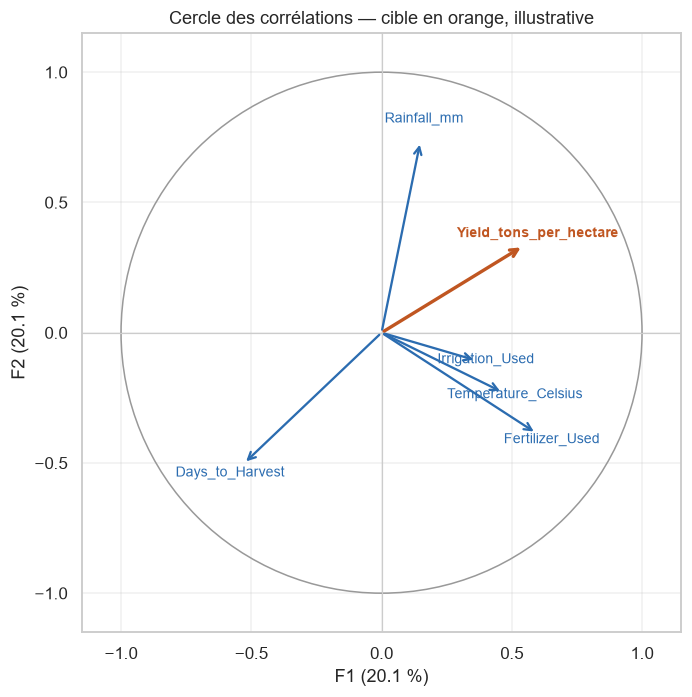

In [58]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_artist(plt.Circle((0, 0), 1, fill=False, color='0.6', linewidth=1))
ax.axhline(0, color='0.8', linewidth=0.8)
ax.axvline(0, color='0.8', linewidth=0.8)

for nom, ligne in cercle.iterrows():
    illustrative = 'illustrative' in nom
    couleur = ORANGE if illustrative else BLUE
    ax.annotate('', xy=(ligne['F1'], ligne['F2']), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=couleur,
                                linewidth=2.2 if illustrative else 1.5))
    ax.text(ligne['F1'] * 1.1, ligne['F2'] * 1.1, nom.replace(' (illustrative)', ''),
            color=couleur, fontsize=9, ha='center',
            fontweight='bold' if illustrative else 'normal')

ax.set(xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), aspect='equal',
       xlabel=f"F1 ({valeurs_propres.loc['F1', 'inertie_%']:.1f} %)",
       ylabel=f"F2 ({valeurs_propres.loc['F2', 'inertie_%']:.1f} %)",
       title='Cercle des corrélations — cible en orange, illustrative')
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

> **Aucune flèche n'atteint le cercle** et aucune ne s'aligne sur une autre : qualité de représentation plafonnant à 0,56, aucune paire corrélée.
>
> La **cible, en variable illustrative**, se place entre `Rainfall_mm` et `Fertilizer_Used` — cohérent avec ses deux liaisons les plus fortes. Mais ce plan ne porte que 40 % de l'inertie et la cible y est mal représentée (0,41) : cette position **confirme** l'analyse supervisée, elle ne la démontre pas.

### 10.2 L'ACP ne voit que le linéaire — contrôle complémentaire

Une corrélation nulle n'exclut pas une dépendance **non linéaire**, qu'une ACP est structurellement incapable de détecter. On teste donc directement : un modèle non linéaire parvient-il à reconstituer une variable à partir des autres ?

In [59]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

echantillon_test = crop_yield.sample(150_000, random_state=RANDOM_STATE)
resultats_dependance = []

for cible_variable in ACTIVES:
    autres = [v for v in ACTIVES if v != cible_variable]
    X_dep = echantillon_test[autres].astype(float)
    y_dep = echantillon_test[cible_variable].astype(float).to_numpy()
    X_tr, X_te, y_tr, y_te = train_test_split(X_dep, y_dep, test_size=0.3,
                                              random_state=RANDOM_STATE)
    modele = HistGradientBoostingRegressor(max_iter=120,
                                           random_state=RANDOM_STATE).fit(X_tr, y_tr)
    r2 = 1 - ((y_te - modele.predict(X_te)) ** 2).mean() / y_te.var()
    resultats_dependance.append({'variable à reconstituer': cible_variable,
                                 'R2 hors échantillon': round(r2, 5)})

pd.DataFrame(resultats_dependance).set_index('variable à reconstituer')

,R2 hors échantillon
variable à reconstituer,
Rainfall_mm,-0.000
Temperature_Celsius,-0.000
Days_to_Harvest,-0.000
Fertilizer_Used,-0.001
Irrigation_Used,-0.001


> **Aucune dépendance, ni linéaire ni non linéaire.** Un gradient boosting, libre de capter n'importe quelle forme de relation, n'arrive à reconstituer aucune des cinq variables à partir des quatre autres : les R² sont nuls ou négatifs — c'est-à-dire moins bons que de prédire la moyenne.
>
> Ce contrôle est nécessaire parce que l'ACP ne mesure que des liaisons **linéaires**. Sans lui, « aucune variable n'en double une autre » resterait une conclusion plus forte que les preuves apportées. Avec lui, elle est établie.

### 10.3 Les variables clés, explicitement

L'ACP ayant établi qu'aucune variable n'est redondante, l'identification des variables clés repose sur les **mesures supervisées** des sections 2.3 et 2.4.

In [60]:
# Croisement des deux sources : liaison a la cible (supervise) et
# part d'inertie propre (ACP, non supervise)
cles = pd.DataFrame(index=ACTIVES)
cles['corrélation_avec_cible'] = [
    crop_yield[v].astype(float).corr(crop_yield[TARGET]) for v in ACTIVES]
cles['part_variance_cible_%'] = [
    100 * eta_squared(crop_yield, v, TARGET) if v in BOOLEAN_FEATURES
    else 100 * crop_yield[v].astype(float).corr(crop_yield[TARGET]) ** 2
    for v in ACTIVES]
cles['redondance_ACP'] = 'aucune'
cles.sort_values('part_variance_cible_%', ascending=False).round(3)

,corrélation_avec_cible,part_variance_cible_%,redondance_ACP
Rainfall_mm,0.765,58.464,aucune
Fertilizer_Used,0.442,19.545,aucune
Irrigation_Used,0.354,12.513,aucune
Temperature_Celsius,0.086,0.732,aucune
Days_to_Harvest,-0.003,0.001,aucune


> **Variables clés retenues**, par pouvoir explicatif décroissant : **`Rainfall_mm`** (relation linéaire, la liaison la plus forte), **`Fertilizer_Used`** (+16 %), **`Irrigation_Used`** (+13 %), **`Temperature_Celsius`** (effet faible mais réel).
>
> **`Days_to_Harvest`** est écartée : ni liaison avec la cible, ni redondance avec les autres — elle n'apporte rien.
>
> **Ce que l'ACP ajoute** : aucune de ces quatre variables ne fait double emploi avec une autre. Elle valide la sélection issue de l'analyse supervisée, elle ne la produit pas.

## 11. Synthèse

### Les six fichiers

| Fichier | Lignes | Qualité | Apport |
|---|---|---|---|
| `crop_yield.csv` | 1 000 000 | Irréprochable en la forme, mais **simulée** | Réponse du rendement aux conditions et aux pratiques |
| `yield_df.csv` | 28 242 | **Amputé puis gonflé** — 13 130 observations réelles | Écarté au profit de `yield.csv` |
| `yield.csv` | 56 717 | Propre ; 5 colonnes constantes sur 12 | **Référentiel retenu** : 212 pays, 1961-2016 |
| `pesticides.csv` | 4 349 | Propre ; 4 colonnes constantes sur 7 | Volume national, peu exploitable |
| `rainfall.csv` | 6 727 | Colonne ` Area`, type texte, 11,6 % non convertibles | **Normale climatique** constante par pays |
| `temp.csv` | 71 311 | 7 534 couples à valeurs divergentes | À agréger par médiane avant toute jointure |

### Variables retenues pour la prédiction

| Variable | Effet mesuré |
|---|---|
| `Rainfall_mm` | Linéaire, r ≈ 0,76 — la plus forte |
| `Fertilizer_Used` | **+16,1 %** (η² = 0,195) |
| `Irrigation_Used` | **+12,9 %** |
| `Temperature_Celsius` | Faible mais non nul |
| Indice de productivité par culture | **À construire** depuis `yield.csv` |

**Écartées, preuves à l'appui** : `Crop`, `Region`, `Soil_Type`, `Weather_Condition`, `Days_to_Harvest` (η² ≈ 0, tests non significatifs sur 1M d'observations) ; `average_rain_fall_mm_per_year` (constante par pays) et `pesticides_tonnes` (r = 0,064). Les quatre qualitatives sont en outre uniformément réparties et mutuellement indépendantes.

### Ce qu'apporte l'ACP

| Résultat | Lecture |
|---|---|
| Cinq valeurs propres égales à 1 | **Aucune redondance linéaire** |
| Un modèle non linéaire ne reconstitue aucune variable (R² ≤ 0) | L'absence de redondance vaut **hors du linéaire** |
| Éboulis plat, axes tournant de 11° à 82° entre sous-échantillons | Axes **non identifiables** |

L'ACP étant **non supervisée**, elle ne désigne pas les variables explicatives : elle établit qu'aucune ne fait double emploi. Elle valide la sélection, elle ne la produit pas.

### Décisions transmises à l'étape de préparation

1. Supprimer les **231 rendements négatifs** (0,023 %, incohérence physique).
2. Construire l'indice depuis **`yield.csv`**, non depuis `yield_df.csv`.
3. **Agréger avant de joindre** ; préférer la jointure gauche à la jointure interne.
4. Harmoniser le vocabulaire des cultures et convertir en **t/ha**.
5. Conserver `Barley` et `Cotton` avec un indicateur « hors référentiel ».
6. Vérifier la **stabilité de l'indice** entre pays et dans le temps.
7. **Ne pas** encoder ni standardiser ici : ces transformations appartiennent au `Pipeline`.

### Limite à porter au rapport métier

L'indice compare des **tonnages**, pas des valeurs économiques. Il dira quelle culture produit le plus à l'hectare, jamais laquelle est **la plus rentable** — alors que c'est le terme de la commande.